# DENTEX: DINO-R50 — chia dữ liệu nội bộ, nhãn thống nhất
Dùng **705 ảnh Level 3** từ `train_quadrant_enumeration_disease.json`, chia cố định seed 42:

- **605 train / 50 validation / 50 test**; các tập không giao nhau.
- Cùng một JSON và mapping Q/N/D cho cả ba tập; học và đánh giá đủ 4 bệnh, gồm Deep Caries.
- Không dùng `validation_triple.json` hoặc `test_data/disease` bên ngoài.
- Chọn `best.pth` bằng mean validation AP, rồi đánh giá test nội bộ một lần sau train. Đây không phải điểm test challenge.

Giữ kiến trúc DINO-R50 4-scale: 900 matching queries, encoder/decoder 6 tầng, loss DINO upstream, backbone pretrained ImageNet, multi-scale resize 480–800/cạnh dài 1333, resize–crop–resize và flip có đổi quadrant. Top-300 query–class, không NMS.

**Lịch train mở rộng**: tối đa 100 epoch; ReduceLROnPlateau giảm LR ×0.1 khi validation AP không cải thiện, patience 5. Early stopping: patience 15, min_delta 0.001 AP, bắt đầu đếm từ epoch 20. Đây là lịch train tùy chỉnh, không còn recipe 12 epoch nguyên bản.

**Metric DENTEX**: Q4 / enumeration8 / diagnosis4; cùng candidate box và confidence sigmoid DINO cho mọi task; AP, AP50, AP75, AR@100 và trung bình ba nhóm. FDI32/joint chỉ là báo cáo phụ. Chọn checkpoint bằng aggregate validation AP của Q/N/D. Định nghĩa metric theo evaluator challenge, nhưng dữ liệu test là split nội bộ.

Kaggle dùng batch 1 × accumulation 16 với AMP; đây là xấp xỉ batch 16, không đồng nhất training nhiều GPU của paper. Bật **GPU + Internet**, gắn dataset và **Run All**. `SMOKE_ONLY=False` để kiểm tra rồi train. Mỗi lần chạy tạo thư mục mới, không resume tự động.

Split khớp **số lượng** của diagnosis trong [DETDet](https://arxiv.org/html/2308.14070): 605/50/50. Không có danh sách image IDs gốc để bảo đảm cùng từng ảnh. Q/N/D dùng chung split vì notebook là mô hình đa nhiệm.

Bổ sung metric phân loại Q/N/D: accuracy, macro-F1, balanced accuracy trên box ghép; exact-match QND; precision/recall/F1 đầu-cuối và localization coverage. IoU>=0.50, score>=0.30, ghép chỉ theo hình học và một prediction/GT. Không thay đổi COCO AP hoặc chọn checkpoint.

Để thêm metric cho checkpoint đã train: đặt `EVALUATE_CHECKPOINT='/kaggle/working/dentex_runs/<run>/best.pth'` rồi Run All. Checkpoint phải còn trong phiên Kaggle hoặc được gắn qua dataset; notebook kiểm tra split và annotation hash, tạo thư mục kết quả mới, không train lại. `None` là train mới.

Minh họa test: chọn 2 ảnh tốt nhất + 2 ảnh tệ nhất theo F1 đầu-cuối QND trên toàn tập test của checkpoint đã chọn bằng validation. Dùng cùng ngưỡng score/IoU của metric phân loại, không dùng confidence trung bình để xếp hạng. Ảnh cực trị chỉ phục vụ phân tích, không đại diện chất lượng trung bình.


## 1. Môi trường
Cài Python 3.11, PyTorch và MMDetection 3.3.0 trong môi trường riêng trên Kaggle.

In [1]:
from pathlib import Path
import os, sys, shutil, subprocess

os.environ['MPLBACKEND'] = 'Agg'
assert Path('/kaggle/working').exists(), 'Chạy notebook này trên Kaggle.'
assert shutil.which('nvidia-smi'), 'Bật GPU trong Kaggle Settings.'
PYTHON = Path('/kaggle/working/.venv_dentex/bin/python')

def run(*args):
    subprocess.run(list(map(str, args)), check=True)

if not PYTHON.exists():
    run(sys.executable, '-m', 'pip', 'install', '-q', 'uv')
    run(shutil.which('uv'), 'python', 'install', '3.11')
    run(shutil.which('uv'), 'venv', '--seed', '--python', '3.11', PYTHON.parent.parent)

check = """import torch, torchvision, mmcv, mmdet, mmengine
from mmcv.ops import MultiScaleDeformableAttention, nms
assert torch.__version__.startswith('2.1.0') and torch.version.cuda == '12.1'
assert torchvision.__version__.startswith('0.16.0')
assert mmcv.__version__ == '2.1.0' and mmdet.__version__ == '3.3.0'
assert mmengine.__version__ == '0.10.7' and torch.cuda.is_available()
"""
if subprocess.run([str(PYTHON), '-c', check], capture_output=True).returncode:
    run(PYTHON, '-m', 'pip', 'install', '-q', 'numpy==1.26.4', 'opencv-python==4.10.0.84')
    run(PYTHON, '-m', 'pip', 'install', '-q', 'torch==2.1.0', 'torchvision==0.16.0',
        '--index-url', 'https://download.pytorch.org/whl/cu121')
    wheel = 'https://download.openmmlab.com/mmcv/dist/cu121/torch2.1.0/mmcv-2.1.0-cp311-cp311-manylinux1_x86_64.whl'
    run(PYTHON, '-m', 'pip', 'install', '-q', '--only-binary=:all:', wheel)
    run(PYTHON, '-m', 'pip', 'install', '-q', 'mmdet==3.3.0', 'mmengine==0.10.7',
        'numpy==1.26.4', 'opencv-python==4.10.0.84', 'scipy==1.13.1',
        'pycocotools==2.0.7', 'pillow', 'yapf==0.40.2')
run(PYTHON, '-c', check + "\nprint('Môi trường sẵn sàng:', torch.cuda.get_device_name(0))")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 97.7 MB/s eta 0:00:00


 Downloaded cpython-3.11.17-linux-x86_64-gnu (download)
Installed Python 3.11.17 in 1.00s
 + cpython-3.11.17-linux-x86_64-gnu (python3.11)
Using CPython 3.11.17
Creating virtual environment with seed packages at: .venv_dentex
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
 + packaging==26.3
 + pip==26.2.2
 + setuptools==84.2.1
 + wheel==0.48.0
Activate with: source .venv_dentex/bin/activate


Môi trường sẵn sàng: Tesla T4


## 2. Cấu hình
Đặt tham số train và tạo thư mục kết quả cho lần chạy này.

In [2]:
%%writefile /kaggle/working/dentex_multitask_dino_r50.py
import os
os.environ['MPLBACKEND'] = 'Agg'
import copy, hashlib, io, json, random, re
from contextlib import redirect_stdout
from datetime import datetime
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

DATA_ROOT = Path('/kaggle/input')
SMOKE_ONLY = False  # False: kiểm tra nhanh rồi train.
SEED = 42
# None: train mới. Đặt đường dẫn best.pth có cùng split để chỉ chấm lại checkpoint.
EVALUATE_CHECKPOINT = None
CLS_SCORE_THRESHOLD = .30  # Cố định trước khi xem test; độc lập VIS_SCORE và COCO AP.
CLS_IOU_THRESHOLD = .50
EPOCHS = 100  # Giới hạn tối đa; validation quyết định thời điểm dừng.
EARLY_STOP_PATIENCE = 15
EARLY_STOP_MIN_DELTA = .001  # AP tuyệt đối trên thang 0–1.
EARLY_STOP_MIN_EPOCHS = 20  # Bắt đầu đếm patience từ epoch 20.
LR_PLATEAU_PATIENCE = 5
LR_FACTOR = .1
BATCH_SIZE = 1
ACCUM_STEPS = 16  # 1 GPU: batch 1 x 16; xấp xỉ batch 16 của paper, không đồng nhất DDP.
TRAIN_SHORT_EDGES = tuple(range(480, 801, 32))
TEST_SHORT_EDGE = 800
MAX_LONG_EDGE = 1333
CROP_RESIZE_SCALES = (400, 500, 600)
CROP_RANGE = (384, 600)
MAX_PER_IMG = 300
GRAD_CLIP_NORM = .1
PAPER_PROFILE = 'DINO-R50-4scale, ImageNet backbone, MMDetection 3.3.0; extended 100ep with early stopping'
INIT_MODE = 'imagenet_backbone'  # Paper R50 baseline: không thêm pretraining COCO detector.
LR, LR_BACKBONE = 1e-4, 1e-5
WEIGHT_DECAY = 1e-4
LAMBDA_Q, LAMBDA_N = 1., 1.
NUM_WORKERS = 2
AMP = True
AMP_INIT_SCALE = 128.  # Khởi đầu thấp để giảm overflow FP16.
MAX_AMP_SKIPS = 8  # Dừng nếu overflow liên tiếp, không âm thầm bỏ cả epoch.
VIS_PER_GROUP = 2  # 2 ảnh tốt nhất + 2 ảnh tệ nhất theo QND F1 đầu-cuối.
DIAG_NAMES = ('Impacted', 'Caries', 'Periapical Lesion', 'Deep Caries')
CHALLENGE_TASKS = ('quadrant', 'enumeration', 'diagnosis')
TASK_NAMES = CHALLENGE_TASKS + ('tooth_fdi', 'joint')
METRIC_NAMES = ('AP50_95', 'AP50', 'AP75', 'AR')
PREDICTION_SCORE = 'DINO diagnosis sigmoid; shared across Q/N/D and supplemental tasks'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
assert torch.cuda.is_available(), 'Cần GPU để chạy DINO.'
OUT = Path('/kaggle/working/dentex_runs') / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True)
(OUT.parent/'latest_run.txt').write_text(str(OUT))
print('Kết quả:', OUT)


Writing /kaggle/working/dentex_multitask_dino_r50.py


## 3. Đọc 705 ảnh Level 3
Đọc một JSON Q/N/D và thư mục xrays tương ứng; kiểm tra nhãn, bbox, ảnh trùng pixel và annotation trùng. Chỉ dùng nguồn này để chia train/validation/test.


In [3]:
%%writefile -a /kaggle/working/dentex_multitask_dino_r50.py
# Ưu tiên bản ductranminh9/dentex nếu Kaggle gắn nhiều dataset.
for directory in (DATA_ROOT/'datasets/ductranminh9/dentex', DATA_ROOT/'dentex'):
    if directory.is_dir():
        DATA_ROOT = directory
        break
print('Dataset:', DATA_ROOT)

candidates = []
for path in DATA_ROOT.rglob('*.json'):
    try:
        data = json.loads(path.read_text(encoding='utf-8-sig'))
    except (ValueError, UnicodeError):
        continue
    if not isinstance(data, dict):
        continue
    image_rows = data.get('images')
    anns = data.get('annotations')
    if (isinstance(image_rows, list) and len(image_rows) == 705
        and isinstance(anns, list) and anns and isinstance(anns[0], dict)
        and all(key in anns[0] for key in ('category_id_1', 'category_id_2', 'category_id_3'))):
        candidates.append((path, data))
assert len(candidates) == 1, f'Cần đúng một JSON Level 3 có 705 ảnh: {[str(p) for p,_ in candidates]}'
ANN_PATH, RAW = candidates[0]

def cats(level):
    values = RAW['categories_' + str(level)]
    if isinstance(values, dict):
        values = list(values.values())
    result = {int(c['id']): str(c['name']).strip() for c in values}
    assert len(result) == len(values), 'Category ID trùng.'
    return result

C1, C2, C3 = (cats(level) for level in (1, 2, 3))
def norm(x): return re.sub('[^a-z0-9]', '', x.lower())

def parse_quadrant(s):
    t = norm(s)
    m = re.fullmatch(r'(?:q|quadrant)?([1-4])',t)
    if m: return int(m.group(1))
    for keys, value in [(['upperright','topright','rightupper'],1),
                         (['upperleft','topleft','leftupper'],2),
                         (['lowerleft','bottomleft','leftlower'],3),
                         (['lowerright','bottomright','rightlower'],4)]:
        if any(k in t for k in keys): return value
    raise ValueError('Unknown quadrant label: '+repr(s))

def parse_tooth(s):
    # FDI = 10*quadrant+position; anatomical names must be parsed BEFORE digits.
    t = norm(s)
    names = {'centralincisor':1, 'incisor1':1, 'lateralincisor':2, 'incisor2':2,
             'canine':3,'firstpremolar':4,'premolar1':4,'secondpremolar':5,
             'premolar2':5,'firstmolar':6,'molar1':6,'secondmolar':7,
             'molar2':7,'thirdmolar':8,'molar3':8,'wisdomtooth':8}
    if t in names: return names[t],None
    digits = re.findall(r'(?<!\d)(?:[1-4][1-8]|[1-8])(?!\d)', s)
    if len(digits) == 1:
        x=int(digits[0])
        return (x%10, x//10 if x>=10 else None)
    raise ValueError('Unknown tooth enumeration label: '+repr(s))


QMAP = {k: parse_quadrant(v) - 1 for k,v in C1.items()}
TMAP = {k: parse_tooth(v) for k,v in C2.items()}
diagnosis_ids = {norm(name): i for i,name in enumerate(DIAG_NAMES)}
diagnosis_ids.update(impactedtooth=0, periapicallesions=2)
DMAP = {k: diagnosis_ids[norm(v)] for k,v in C3.items()}
assert set(QMAP.values()) == set(range(4))
assert {position for position,_ in TMAP.values()} == set(range(1, 9))
assert set(DMAP.values()) == set(range(4))
print('JSON:', ANN_PATH)
print('Nhãn Q/N/D:', C1, C2, C3, sep='\n')

IMAGE_DIR = ANN_PATH.parent / 'xrays'
assert IMAGE_DIR.is_dir(), f'Thiếu thư mục ảnh: {IMAGE_DIR}'
print('Ảnh Level 3:', IMAGE_DIR)

def find_image(im):
    name = str(im['file_name']).replace('\\', '/')
    path = IMAGE_DIR / Path(name).name
    if not path.is_file():
        raise FileNotFoundError(f'Thiếu ảnh Level 3: {path}')
    return path

images, seen = {}, {}
for im in RAW['images']:
    iid = int(im['id'])
    path = find_image(im)
    with Image.open(path) as fp:
        rgb = fp.convert('RGB')
        w, h = rgb.size
        digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
    assert (w,h) == (int(im['width']), int(im['height'])), path
    assert iid not in images, f'Image ID trùng: {iid}'
    assert digest not in seen, f'Ảnh trùng pixel: {seen.get(digest)} và {iid}'
    seen[digest] = iid
    images[iid] = dict(id=iid, file_name=str(path), width=w, height=h)

def read_annotations(raw_annotations):
    annotations = defaultdict(list)
    seen = {}
    duplicates = []
    clipped = 0
    for a in raw_annotations:
        iid = int(a['image_id'])
        im = images[iid]
        q = QMAP[int(a['category_id_1'])]
        n, fdi_q = TMAP[int(a['category_id_2'])]
        d = DMAP[int(a['category_id_3'])]
        assert fdi_q is None or fdi_q == q + 1, a
        x, y, w, h = map(float, a['bbox'])
        assert np.isfinite([x,y,w,h]).all() and w > 0 and h > 0, a
        # Chỉ bỏ bản trùng hoàn toàn theo nhãn detection, trước khi clip bbox.
        key = (iid, x, y, w, h, q, n, d)
        if key in seen:
            duplicates.append(dict(kept_id=seen[key], removed_annotation=a))
            continue
        box = [max(0.,x), max(0.,y), min(im['width'],x+w), min(im['height'],y+h)]
        assert box[2] > box[0] and box[3] > box[1], a
        clipped += box != [x,y,x+w,y+h]
        seen[key] = a.get('id')
        annotations[iid].append(dict(box=box, quadrant=q, number=n-1, diagnosis=d))
    return annotations, duplicates, clipped

annotations, duplicates, clipped = read_annotations(RAW['annotations'])
kept = sum(map(len, annotations.values()))
audit = dict(source_json=str(ANN_PATH), images=len(images),
             raw_annotations=len(RAW['annotations']), kept_annotations=kept,
             removed_duplicates=len(duplicates), clipped_boxes=clipped,
             duplicate_details=duplicates)
(OUT/'data_audit.json').write_text(json.dumps(audit, indent=2))
print(f'{len(images)} ảnh | {kept} bbox | bỏ {len(duplicates)} annotation trùng | clip {clipped} bbox.')
print('Số bbox theo bệnh:', Counter(DIAG_NAMES[a['diagnosis']] for rows in annotations.values() for a in rows))

data_audit = audit
data_audit['protocol'] = 'internal_705_seed42_605_50_50__validation_best__test_once'
data_audit['annotation_sha256'] = hashlib.sha256(ANN_PATH.read_bytes()).hexdigest()
(OUT/'data_audit.json').write_text(json.dumps(data_audit, indent=2), encoding='utf-8')


Appending to /kaggle/working/dentex_multitask_dino_r50.py


## 4. Chia train / validation / test nội bộ
Shuffle danh sách image IDs với seed 42: 605/50/50, khớp số lượng ảnh diagnosis của DETDet; danh sách ảnh do seed 42 quyết định. Lưu splits.json và thống kê đủ 4 bệnh của từng split.


In [4]:
%%writefile -a /kaggle/working/dentex_multitask_dino_r50.py
ids = list(images)
random.Random(SEED).shuffle(ids)
splits = {'train': ids[:605], 'val': ids[605:655], 'test': ids[655:]}
assert {name: len(rows) for name, rows in splits.items()} == {'train': 605, 'val': 50, 'test': 50}
(OUT/'splits.json').write_text(json.dumps(splits, indent=2))
print({name: len(rows) for name,rows in splits.items()})

def task_label(a,task):
    if task=='quadrant': return a['quadrant']
    if task=='enumeration': return a['number']
    if task=='tooth_fdi': return 8*a['quadrant']+a['number']
    if task=='diagnosis': return a['diagnosis']
    if task=='joint': return 4*(8*a['quadrant']+a['number'])+a['diagnosis']
    raise ValueError(task)

CATEGORY_NAMES={
    'enumeration':[str(n) for n in range(1,9)],
    'quadrant':[f'Q{i}' for i in range(1,5)],
    'tooth_fdi':[f'{q}{n}' for q in range(1,5) for n in range(1,9)],
    'diagnosis':list(DIAG_NAMES),
    'joint':[f'{q}{n}__{d}' for q in range(1,5) for n in range(1,9) for d in DIAG_NAMES]
}

def build_gt(task, split, image_ids=None):
    selected = splits[split] if image_ids is None else image_ids
    ims=[images[i] for i in selected]
    an=[]
    for iid in selected:
        for a in annotations[iid]:
            x0,y0,x1,y1=a['box']
            an.append({'id':len(an)+1,'image_id':iid,'bbox':[x0,y0,x1-x0,y1-y0],
                       'area':(x1-x0)*(y1-y0),'iscrowd':0,'category_id':task_label(a,task)+1})
    return {'info':{'description':'DENTEX internal seed42 '+split+' '+task},'licenses':[],
            'images':ims,'annotations':an,
            'categories':[{'id':i+1,'name':n,'supercategory':task}
                          for i,n in enumerate(CATEGORY_NAMES[task])]}

assert not (set(splits['train']) & set(splits['val']) or
            set(splits['train']) & set(splits['test']) or
            set(splits['val']) & set(splits['test']))
assert set().union(*map(set, splits.values())) == set(images)
data_audit['split_counts'] = {name: len(ids) for name,ids in splits.items()}
data_audit['diagnosis_counts'] = {
    name: dict(Counter(DIAG_NAMES[a['diagnosis']] for iid in ids for a in annotations[iid]))
    for name,ids in splits.items()}
(OUT/'data_audit.json').write_text(json.dumps(data_audit, indent=2), encoding='utf-8')


Appending to /kaggle/working/dentex_multitask_dino_r50.py


## 5. DataLoader và augmentation theo DINO
Flip → chọn random multi-scale resize hoặc resize–crop–resize. Crop giữ đúng liên kết bbox/Q/N/D; flip đổi Q1↔Q2, Q3↔Q4. Test và smoke dùng resize cố định, không augmentation.


In [5]:
%%writefile -a /kaggle/working/dentex_multitask_dino_r50.py
from mmdet.structures import DetDataSample
from mmengine.structures import InstanceData

# DINO/DETR-style resize/flip/crop, extended to keep DENTEX Q/N/D aligned.
# Reference: IDEA-Research/DINO datasets/transforms.py (Apache-2.0).
def resize_dentex(image, target, short_edge, max_size=None):
    width, height = image.size
    size = int(short_edge)
    if max_size is not None and max(width, height)/min(width, height)*size > max_size:
        size = int(round(max_size*min(width, height)/max(width, height)))
    size = max(1, size)
    if width < height:
        rw, rh = size, max(1, int(size*height/width))
    else:
        rh, rw = size, max(1, int(size*width/height))
    result = dict(target)
    sx, sy = rw/width, rh/height
    result['boxes'] = target['boxes']*target['boxes'].new_tensor([sx, sy, sx, sy])
    return image.resize((rw, rh), Image.Resampling.BILINEAR), result, (sx, sy)


def flip_dentex(image, target):
    width, _ = image.size
    result = dict(target)
    boxes = target['boxes']
    result['boxes'] = boxes[:, [2, 1, 0, 3]]*boxes.new_tensor([-1, 1, -1, 1])
    result['boxes'] += boxes.new_tensor([width, 0, width, 0])
    # Mirroring changes FDI quadrant; position N and diagnosis remain the same.
    remap = target['q_labels'].new_tensor([1, 0, 3, 2])
    result['q_labels'] = remap[target['q_labels']]
    return image.transpose(Image.Transpose.FLIP_LEFT_RIGHT), result


def crop_dentex(image, target, region):
    top, left, height, width = region
    boxes = target['boxes']-target['boxes'].new_tensor([left, top, left, top])
    boxes[:, 0::2].clamp_(0, width)
    boxes[:, 1::2].clamp_(0, height)
    keep = (boxes[:, 2] > boxes[:, 0]) & (boxes[:, 3] > boxes[:, 1])
    result = {name: value[keep] for name, value in target.items()}
    result['boxes'] = boxes[keep]
    return image.crop((left, top, left+width, top+height)), result


def transform_dentex(image, target, augment):
    flipped = False
    scale_x, scale_y = 1., 1.
    if augment:
        if random.random() < .5:
            image, target = flip_dentex(image, target)
            flipped = True
        if random.random() >= .5:
            image, target, (sx, sy) = resize_dentex(image, target, random.choice(CROP_RESIZE_SCALES))
            scale_x *= sx
            scale_y *= sy
            # DINO samples width/height independently, then a random crop origin.
            min_crop, max_crop = CROP_RANGE
            cw = random.randint(min(min_crop, image.width), min(image.width, max_crop))
            ch = random.randint(min(min_crop, image.height), min(image.height, max_crop))
            top = int(torch.randint(0, image.height-ch+1, (1,)).item())
            left = int(torch.randint(0, image.width-cw+1, (1,)).item())
            image, target = crop_dentex(image, target, (top, left, ch, cw))
        short_edge = random.choice(TRAIN_SHORT_EDGES)
    else:
        short_edge = TEST_SHORT_EDGE
    image, target, (sx, sy) = resize_dentex(image, target, short_edge, MAX_LONG_EDGE)
    return image, target, dict(scale_factor=(scale_x*sx, scale_y*sy),
                              flip=flipped, flip_direction='horizontal' if flipped else None)


class DentexFullyLabeled(Dataset):
    def __init__(self, split, augment=None):
        self.ids = splits[split]
        self.augment = split == 'train' if augment is None else augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        iid = self.ids[index]
        im = images[iid]
        rows = annotations[iid]
        target = dict(
            boxes=torch.tensor([a['box'] for a in rows], dtype=torch.float32).reshape(-1, 4),
            labels=torch.tensor([a['diagnosis'] for a in rows], dtype=torch.long),
            q_labels=torch.tensor([a['quadrant'] for a in rows], dtype=torch.long),
            n_labels=torch.tensor([a['number'] for a in rows], dtype=torch.long))
        with Image.open(im['file_name']) as fp:
            rgb, target, meta = transform_dentex(fp.convert('RGB'), target, self.augment)
            arr = np.asarray(rgb, dtype=np.uint8).copy()
        # MMDet's inherited preprocessor expects BGR uint8 and normalizes to RGB.
        tensor = torch.from_numpy(arr[:, :, ::-1].copy()).permute(2, 0, 1)
        gt = InstanceData()
        gt.bboxes = target['boxes']
        gt.labels = target['labels']
        gt.q_labels = target['q_labels']
        gt.n_labels = target['n_labels']
        sample = DetDataSample()
        sample.set_metainfo(dict(img_id=iid, img_path=im['file_name'],
                                 ori_shape=(im['height'], im['width']),
                                 img_shape=arr.shape[:2], **meta))
        sample.gt_instances = gt
        return dict(inputs=tensor, data_samples=sample)


def collate(items):
    return dict(inputs=[item['inputs'] for item in items],
                data_samples=[item['data_samples'] for item in items])


train_dl = DataLoader(DentexFullyLabeled('train'), batch_size=BATCH_SIZE, shuffle=True,
                      collate_fn=collate, num_workers=NUM_WORKERS, pin_memory=True)
val_dl = DataLoader(DentexFullyLabeled('val', augment=False), batch_size=1, shuffle=False,
                    collate_fn=collate, num_workers=NUM_WORKERS)
test_dl = DataLoader(DentexFullyLabeled('test', augment=False), batch_size=1, shuffle=False,
                     collate_fn=collate, num_workers=NUM_WORKERS)


Appending to /kaggle/working/dentex_multitask_dino_r50.py


## 6. Model DINO-R50
Kế thừa config DINO 4-scale của MMDetection 3.3.0; kiểm tra các tham số kiến trúc/loss và lưu model_config.py cùng experiment.json. Q/N là hai head bổ sung ở matching queries decoder cuối.


In [6]:
%%writefile -a /kaggle/working/dentex_multitask_dino_r50.py
import mmdet
from mmengine.config import Config
from mmdet.registry import MODELS
from mmdet.utils import register_all_modules
from mmdet.models.dense_heads import DINOHead
from mmdet.structures.bbox import bbox_cxcywh_to_xyxy

register_all_modules(init_default_scope=True)
configs=list(Path(mmdet.__file__).parent.rglob('dino-4scale_r50_8xb2-12e_coco.py'))
assert len(configs)==1, f'MMDet DINO config not found/unexpected: {configs}'
cfg=Config.fromfile(str(configs[0]))
cfg.model.bbox_head.num_classes=4
cfg.model.bbox_head.type='DentexMultiTaskDINOHead'
cfg.model.data_preprocessor.pad_size_divisor=1
cfg.model.test_cfg.max_per_img=MAX_PER_IMG
# Giữ nguyên CDN/attention/box refinement/loss của upstream; không thay matcher bằng Q/N.
assert cfg.model.backbone.type == 'ResNet' and cfg.model.backbone.depth == 50
assert cfg.model.neck.num_outs == 4 and cfg.model.neck.out_channels == 256
assert cfg.model.as_two_stage and cfg.model.with_box_refine
assert cfg.model.bbox_head.loss_cls.use_sigmoid
assert cfg.model.bbox_head.loss_cls.loss_weight == 1.
assert cfg.model.bbox_head.loss_bbox.loss_weight == 5.
assert cfg.model.bbox_head.loss_iou.loss_weight == 2.
assert cfg.model.dn_cfg.box_noise_scale == 1.
assert cfg.model.dn_cfg.label_noise_scale == .5
cfg.dump(str(OUT/'model_config.py'))

experiment = dict(
    paper_profile=PAPER_PROFILE, init_mode=INIT_MODE,
    epochs=EPOCHS,
    early_stopping=dict(patience=EARLY_STOP_PATIENCE, min_delta=EARLY_STOP_MIN_DELTA,
                        min_epochs=EARLY_STOP_MIN_EPOCHS),
    scheduler=dict(type='ReduceLROnPlateau', mode='max', patience=LR_PLATEAU_PATIENCE,
                   factor=LR_FACTOR, threshold=EARLY_STOP_MIN_DELTA,
                   min_lr=[LR_BACKBONE*.001, LR*.001]),
    classification_evaluation=dict(score_threshold=CLS_SCORE_THRESHOLD, iou_threshold=CLS_IOU_THRESHOLD,
                                   matching='geometry only, one-to-one', candidate='top-1 diagnosis per query'),
    evaluation=dict(tasks=list(CHALLENGE_TASKS), metrics=list(METRIC_NAMES),
                    aggregate='arithmetic mean of Q/N/D', AR='COCO stats[8], maxDets=100',
                    score=PREDICTION_SCORE, shared_candidates=True),
    batch_size=BATCH_SIZE, accumulation=ACCUM_STEPS,
    nominal_effective_batch=BATCH_SIZE*ACCUM_STEPS,
    lr=LR, lr_backbone=LR_BACKBONE, weight_decay=WEIGHT_DECAY,
    gradient_clip=GRAD_CLIP_NORM, amp=AMP, amp_init_scale=AMP_INIT_SCALE,
    augmentation=dict(short_edges=list(TRAIN_SHORT_EDGES), max_long_edge=MAX_LONG_EDGE,
                      crop_resize=list(CROP_RESIZE_SCALES), crop_range=list(CROP_RANGE),
                      horizontal_flip=.5, quadrant_remap=[1,0,3,2]),
    test_short_edge=TEST_SHORT_EDGE, topk_query_class=MAX_PER_IMG,
    extra_heads=dict(quadrant=4, position=8, supervision='final matching queries only',
                     lambda_q=LAMBDA_Q, lambda_n=LAMBDA_N),
    protocol='internal_705_seed42_605_50_50__validation_best__test_once',
    split_seed=SEED, split_counts={name: len(ids) for name,ids in splits.items()},
    annotation_sha256=data_audit['annotation_sha256'],
    evaluated_diagnoses=list(DIAG_NAMES),
    versions=dict(torch=torch.__version__, mmdet=mmdet.__version__),
    source_sha256=hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
    references=[
        'https://arxiv.org/abs/2203.03605',
        'https://github.com/IDEA-Research/DINO/blob/main/config/DINO/DINO_4scale.py',
        'https://github.com/open-mmlab/mmdetection/tree/v3.3.0/configs/dino'])
(OUT/'experiment.json').write_text(json.dumps(experiment, indent=2), encoding='utf-8')
print('Paper profile:', PAPER_PROFILE, '| nominal batch:', BATCH_SIZE*ACCUM_STEPS)

@MODELS.register_module()
class DentexMultiTaskDINOHead(DINOHead):
    """DINO diagnosis + bbox, thêm hai head Q và N."""
    def _init_layers(self):
        super()._init_layers()
        self.q_head=nn.Linear(self.embed_dims,4)
        self.n_head=nn.Linear(self.embed_dims,8)

    def loss(self, hidden_states, references, enc_outputs_class, enc_outputs_coord,
             batch_data_samples, dn_meta):
        losses=super().loss(hidden_states,references,enc_outputs_class,
                            enc_outputs_coord,batch_data_samples,dn_meta)
        n_dn=int(dn_meta.get('num_denoising_queries',0)) if dn_meta else 0
        assert hidden_states.shape[2]-n_dn==900, (hidden_states.shape, n_dn)
        # Bỏ DN queries; Q/N dùng cùng matching D+box như DINO.
        with torch.no_grad():
            cls,reg=self(hidden_states.detach(),references)
        q_logits=self.q_head(hidden_states[-1,:,n_dn:])
        n_logits=self.n_head(hidden_states[-1,:,n_dn:])
        q_losses=[];n_losses=[]
        for i,ds in enumerate(batch_data_samples):
            h,w=ds.metainfo['img_shape']
            bb=bbox_cxcywh_to_xyxy(reg[-1,i,n_dn:]) * reg.new_tensor([w,h,w,h])
            pred=InstanceData(scores=cls[-1,i,n_dn:],bboxes=bb)
            gt=ds.gt_instances
            assigned=self.assigner.assign(pred_instances=pred,gt_instances=gt,img_meta=ds.metainfo)
            pos=torch.nonzero(assigned.gt_inds>0).flatten()
            if pos.numel():
                gid=assigned.gt_inds[pos]-1
                q_losses.append(F.cross_entropy(q_logits[i,pos],gt.q_labels[gid]))
                n_losses.append(F.cross_entropy(n_logits[i,pos],gt.n_labels[gid]))
        # Batch không có GT: loss Q/N bằng 0, vẫn nối với graph.
        losses['loss_quadrant']=LAMBDA_Q*(torch.stack(q_losses).mean() if q_losses
                                         else q_logits.sum()*0)
        losses['loss_enumeration']=LAMBDA_N*(torch.stack(n_losses).mean() if n_losses
                                            else n_logits.sum()*0)
        return losses

assert (cfg.model.num_queries,cfg.model.encoder.num_layers,
        cfg.model.decoder.num_layers)==(900,6,6)
assert cfg.model.encoder.layer_cfg.self_attn_cfg.num_levels==4

def make_model():
    model=MODELS.build(copy.deepcopy(cfg.model))
    model.init_weights()
    return model.cuda()


Appending to /kaggle/working/dentex_multitask_dino_r50.py


## 7. Đánh giá theo định nghĩa DENTEX
Enumeration là 8 vị trí trong quadrant, độc lập với Q4; không dùng FDI32 thay thế. Mọi task dùng cùng top-300 candidate query–class, bbox và sigmoid diagnosis score, không deduplicate riêng Q/N. COCO mặc định maxDets=[1,10,100]: AP=stats[0], AP50=stats[1], AP75=stats[2], AR=stats[8]. Aggregate là trung bình Q/N/D; FDI32 và joint là metric phụ.

Đối chiếu [evaluator chính thức](https://github.com/ibrahimethemhamamci/DENTEX/blob/main/DentexChallenge-AlgorithmPhases-Evaluation-Docker/evaluation.py). Evaluator yêu cầu dùng chung probability, không quy định công thức confidence; notebook giữ sigmoid score của DINO.

Metric phân loại bổ sung dùng diagnosis top-1 mỗi query (không dùng các hypothesis bệnh phụ), score>=CLS_SCORE_THRESHOLD. Ghép box bằng IoU tối đa hóa số cặp hợp lệ rồi tổng IoU, không dùng nhãn. Accuracy/macro-F1/balanced accuracy chỉ trên các cặp ghép; precision/recall/F1 đầu-cuối tính cả bỏ sót/dự đoán thừa. Macro tính trên lớp có GT trong phạm vi tương ứng; lớp vắng GT có support=0. Mẫu số 0 được ghi null. Confusion matrix có thêm hàng Unmatched prediction và cột Missed GT. Joint exact-match yêu cầu đúng cả Q/N/D.


In [7]:
%%writefile -a /kaggle/working/dentex_multitask_dino_r50.py
def decode_dentex_candidates(cls_logits, bbox_preds, q_logits, n_logits,
                             image_id, ori_shape, max_per_img):
    # Same selection as original DINO PostProcess: sigmoid, flatten query x class,
    # take top-k BEFORE applying any per-class evaluation scope.
    probabilities = cls_logits.float().sigmoid()
    scores, indexes = probabilities.flatten().topk(min(max_per_img, probabilities.numel()))
    diagnosis = indexes % probabilities.shape[-1]
    query_indexes = indexes // probabilities.shape[-1]
    pq, quadrant = q_logits.float().softmax(-1).max(-1)
    pn, position = n_logits.float().softmax(-1).max(-1)
    # Original DINO PostProcess scales raw xyxy boxes without clipping to borders.
    boxes = bbox_cxcywh_to_xyxy(bbox_preds.float())
    height, width = ori_shape
    boxes = (boxes*boxes.new_tensor([width, height, width, height])).cpu().tolist()
    pq, pn = pq.cpu().tolist(), pn.cpu().tolist()
    quadrant, position = quadrant.cpu().tolist(), position.cpu().tolist()
    results = []
    for score, d, qi in zip(scores.cpu().tolist(), diagnosis.cpu().tolist(), query_indexes.cpu().tolist()):
        x0, y0, x1, y1 = boxes[qi]
        if x1 <= x0 or y1 <= y0:
            continue
        q, n = int(quadrant[qi]), int(position[qi])
        fdi = 8*q+n
        # One candidate, one confidence for every task, as in the DENTEX evaluator.
        # Retain DINO's diagnosis sigmoid score; Q/N supply categorical labels.
        values = {'quadrant': q, 'enumeration': n, 'diagnosis': d,
                  'tooth_fdi': fdi, 'joint': 4*fdi+d}
        for task, category in values.items():
            results.append((task, dict(image_id=int(image_id), category_id=category+1,
                _diagnosis=int(d), _query_index=int(qi),
                bbox=[x0, y0, x1-x0, y1-y0], score=float(score))))
    return results


@torch.inference_mode()
def predict_multitask(model, raw):
    model.eval()
    batch = model.data_preprocessor(raw, training=False)
    samples = batch['data_samples']
    with torch.autocast('cuda', enabled=AMP):
        features = model.extract_feat(batch['inputs'])
        decoder = model.forward_transformer(features, samples)
        hidden = decoder['hidden_states']
        cls, reg = model.bbox_head(hidden, decoder['references'])
        q_logits = model.bbox_head.q_head(hidden[-1])
        n_logits = model.bbox_head.n_head(hidden[-1])
    results = []
    for i, sample in enumerate(samples):
        results.extend(decode_dentex_candidates(
            cls[-1, i], reg[-1, i], q_logits[i], n_logits[i],
            sample.metainfo['img_id'], sample.metainfo['ori_shape'], MAX_PER_IMG))
    return results


from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def coco_metrics(gt_data, predictions):
    # Giữ output gọn; summarize() cần chạy để tạo ev.stats.
    with redirect_stdout(io.StringIO()):
        gt = COCO()
        gt.dataset = gt_data
        gt.createIndex()
        if predictions:
            dt = gt.loadRes(predictions)
        else:
            dt = COCO()
            dt.dataset = {**gt_data, 'annotations': []}
            dt.createIndex()
        ev = COCOeval(gt, dt, 'bbox')
        ev.params.imgIds = [im['id'] for im in gt_data['images']]
        ev.evaluate()
        ev.accumulate()
        ev.summarize()
    return dict(AP50_95=float(ev.stats[0]), AP50=float(ev.stats[1]),
                AP75=float(ev.stats[2]), AR=float(ev.stats[8]),
                classes_with_gt=len({a['category_id'] for a in gt_data['annotations']}))

def challenge_aggregate(metrics):
    # FDI32 and joint are supplemental and never enter the challenge mean.
    return {name: float(np.mean([metrics[task][name] for task in CHALLENGE_TASKS]))
            for name in METRIC_NAMES}


def qnd_classification_metrics(gt_data, predictions, score_threshold=.30, iou_threshold=.50):
    """Supplemental Q/N/D metrics; geometry-only maximum-cardinality IoU matching."""
    from scipy.optimize import linear_sum_assignment
    assert 0 <= score_threshold <= 1 and 0 < iou_threshold <= 1
    gt_by_image = defaultdict(list)
    for row in gt_data['annotations']:
        gt_by_image[int(row['image_id'])].append(row)
    selected_ids = {int(row['id']) for row in gt_data['images']}
    # DINO may emit multiple diagnosis hypotheses per query. Classification uses
    # its highest-score diagnosis, once per query, before the confidence cutoff.
    candidates = {}
    fallback = False
    for row in predictions:
        iid = int(row['image_id'])
        if iid not in selected_ids:
            raise ValueError(f'Prediction image_id {iid} is outside the evaluated split.')
        if '_query_index' in row:
            key = (iid, int(row['_query_index']))
        else:
            fallback = True
            key = (iid, tuple(row['bbox']))
        if key not in candidates or row['score'] > candidates[key]['score']:
            candidates[key] = row
    pred_by_image = defaultdict(list)
    for row in candidates.values():
        if row['score'] >= score_threshold:
            pred_by_image[int(row['image_id'])].append(row)

    def labels(row):
        label = int(row['category_id'])-1
        if not 0 <= label < 128:
            raise ValueError(f'Invalid joint category: {label+1}')
        fdi, d = divmod(label, 4)
        q, n = divmod(fdi, 8)
        return q, n, d

    def ious(gt, pred):
        a = np.asarray([r['bbox'] for r in gt], dtype=float).reshape(-1, 4)
        b = np.asarray([r['bbox'] for r in pred], dtype=float).reshape(-1, 4)
        a1, b1 = a[:, :2]+a[:, 2:], b[:, :2]+b[:, 2:]
        inter = np.maximum(0, np.minimum(a1[:, None], b1)-np.maximum(a[:, None, :2], b[:, :2])).prod(-1)
        union = (a[:, 2]*a[:, 3])[:, None]+(b[:, 2]*b[:, 3])[None, :]-inter
        return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)

    task_names = ('quadrant', 'enumeration', 'diagnosis')
    class_names = ([f'Q{i}' for i in range(1, 5)], [str(i) for i in range(1, 9)], list(DIAG_NAMES))
    matrices = {task: np.zeros((len(names)+1, len(names)+1), dtype=np.int64)
                for task, names in zip(task_names, class_names)}
    total_gt = total_pred = matched = exact = 0
    matched_ious = []
    for iid in sorted(selected_ids):
        gt, pred = gt_by_image[iid], pred_by_image[iid]
        total_gt += len(gt)
        total_pred += len(pred)
        pairs = []
        if gt and pred:
            overlaps = ious(gt, pred)
            valid = overlaps >= iou_threshold
            # A valid match outweighs all possible IoU tie-break gains. Optimize
            # number of valid pairs first, then their total IoU; labels never enter.
            reward = valid*(min(len(gt), len(pred))+1+overlaps)
            gi, pi = linear_sum_assignment(-reward)
            pairs = [(int(g), int(p)) for g, p in zip(gi, pi) if valid[g, p]]
            matched_ious.extend(float(overlaps[g, p]) for g, p in pairs)
        used_gt, used_pred = {g for g, _ in pairs}, {p for _, p in pairs}
        for g, p in pairs:
            truth, guess = labels(gt[g]), labels(pred[p])
            matched += 1
            exact += int(truth == guess)
            for index, task in enumerate(task_names):
                matrices[task][truth[index], guess[index]] += 1
        for g, row in enumerate(gt):
            if g not in used_gt:
                for index, task in enumerate(task_names):
                    matrices[task][labels(row)[index], -1] += 1
        for p, row in enumerate(pred):
            if p not in used_pred:
                for index, task in enumerate(task_names):
                    matrices[task][-1, labels(row)[index]] += 1

    def ratio(a, b):
        return float(a/b) if b else None

    def summarize(matrix):
        tp = np.diag(matrix).astype(float)
        support, predicted = matrix.sum(1), matrix.sum(0)
        rows = []
        for i in range(len(tp)):
            denom = int(support[i]+predicted[i])
            rows.append(dict(precision=ratio(tp[i], predicted[i]), recall=ratio(tp[i], support[i]),
                             f1=ratio(2*tp[i], denom), support=int(support[i]),
                             predicted=int(predicted[i]), correct=int(tp[i])))
        supported = [r for r in rows if r['support'] > 0]
        return rows, dict(
            macro_f1=float(np.mean([r['f1'] for r in supported])) if supported else None,
            balanced_accuracy=float(np.mean([r['recall'] for r in supported])) if supported else None)

    result = dict(protocol=dict(score_threshold=score_threshold, iou_threshold=iou_threshold,
                               matching='class-agnostic maximum-cardinality then maximum-total-IoU; one-to-one',
                               classification_candidates='one highest-score diagnosis per query; no NMS',
                               query_key_fallback_to_bbox=fallback,
                               macro_average='classes with GT support; unsupported classes reported as null',
                               units='fractions 0–1; null when denominator is zero'),
                  localization=dict(gt_count=total_gt, prediction_count=total_pred, matched_count=matched,
                                    missed_gt=total_gt-matched, unmatched_predictions=total_pred-matched,
                                    recall=ratio(matched, total_gt), precision=ratio(matched, total_pred),
                                    f1=ratio(2*matched, total_gt+total_pred),
                                    mean_matched_iou=float(np.mean(matched_ious)) if matched_ious else None),
                  tasks={})
    for task, names in zip(task_names, class_names):
        full = matrices[task]
        conditional = full[:-1, :-1]
        per_class, averages = summarize(conditional)
        # Full confusion contributes missed GT to FN and unmatched predictions to
        # FP, without pretending either is a real class in macro averages.
        tp = np.diag(conditional)
        end_rows = []
        for i, name in enumerate(names):
            support, predicted = int(full[i].sum()), int(full[:, i].sum())
            end_rows.append(dict(label=name, support=support, predicted=predicted, correct=int(tp[i]),
                                 precision=ratio(tp[i], predicted), recall=ratio(tp[i], support),
                                 f1=ratio(2*tp[i], support+predicted)))
        supported_end = [r for r in end_rows if r['support'] > 0]
        correct = int(tp.sum())
        result['tasks'][task] = dict(
            labels=names, matched_accuracy=ratio(correct, matched), **averages,
            correct_count=correct, end_to_end_recall=ratio(correct, total_gt),
            end_to_end_precision=ratio(correct, total_pred),
            end_to_end_f1=ratio(2*correct, total_gt+total_pred),
            end_to_end_macro_f1=float(np.mean([r['f1'] for r in supported_end])) if supported_end else None,
            per_class_matched=[dict(label=name, **row) for name, row in zip(names, per_class)],
            per_class_end_to_end=end_rows,
            confusion_matched=conditional.tolist(), confusion_with_misses=full.tolist(),
            confusion_rows=names+['Unmatched prediction'], confusion_columns=names+['Missed GT'])
    result['joint'] = dict(exact_match_accuracy=ratio(exact, matched), correct_count=exact,
                           end_to_end_recall=ratio(exact, total_gt),
                           end_to_end_precision=ratio(exact, total_pred),
                           end_to_end_f1=ratio(2*exact, total_gt+total_pred))
    return result


def save_classification_report(report):
    import csv
    import matplotlib.pyplot as plt
    (OUT/'test_classification_metrics.json').write_text(
        json.dumps(report, indent=2, allow_nan=False), encoding='utf-8')
    columns = ['task', 'matched_accuracy', 'macro_f1', 'balanced_accuracy',
               'end_to_end_precision', 'end_to_end_recall', 'end_to_end_f1', 'end_to_end_macro_f1']
    with (OUT/'test_classification_summary.csv').open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=columns)
        writer.writeheader()
        for task, row in report['tasks'].items():
            writer.writerow(dict(task=task, **{name: row.get(name) for name in columns[1:]}))
        row = report['joint']
        writer.writerow(dict(task='joint_QND', matched_accuracy=row['exact_match_accuracy'],
                             **{name: row[name] for name in ['end_to_end_precision', 'end_to_end_recall', 'end_to_end_f1']}))
    columns = ['task', 'scope', 'label', 'support', 'predicted', 'correct', 'precision', 'recall', 'f1']
    with (OUT/'test_classification_per_class.csv').open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=columns)
        writer.writeheader()
        for task, row in report['tasks'].items():
            for scope in ['matched', 'end_to_end']:
                for item in row['per_class_'+scope]:
                    writer.writerow(dict(task=task, scope=scope, **item))
    fig, axes = plt.subplots(1, 3, figsize=(21, 7))
    for ax, (task, row) in zip(axes, report['tasks'].items()):
        matrix = np.asarray(row['confusion_with_misses'])
        ax.imshow(matrix, cmap='Blues')
        for (i, j), count in np.ndenumerate(matrix):
            ax.text(j, i, str(count), ha='center', va='center', fontsize=8,
                    color='white' if count > matrix.max()/2 else 'black')
        ax.set(xticks=range(matrix.shape[1]), xticklabels=row['confusion_columns'],
               yticks=range(matrix.shape[0]), yticklabels=row['confusion_rows'],
               xlabel='Predicted', ylabel='Ground truth', title=task)
        ax.tick_params(axis='x', labelrotation=65)
    cfg = report['protocol']
    fig.suptitle(f"Test Q/N/D confusion: score >= {cfg['score_threshold']}, IoU >= {cfg['iou_threshold']} (counts)")
    fig.tight_layout()
    fig.savefig(OUT/'test_classification_confusion.png', dpi=150)
    plt.close(fig)
    print('Classification protocol:', report['protocol'])
    print('Localization coverage:', report['localization'])
    for task, row in report['tasks'].items():
        print(task, {key: row[key] for key in ['matched_accuracy', 'macro_f1', 'balanced_accuracy',
                                             'end_to_end_recall', 'end_to_end_f1']})
    print('Joint Q/N/D:', report['joint'])


def evaluate(model, loader, split, image_ids=None):
    predictions = {task: [] for task in TASK_NAMES}
    classification_candidates = []
    for raw in loader:
        for task, detection in predict_multitask(model, raw):
            if split == 'test' and task == 'joint':
                classification_candidates.append(dict(detection))
            detection = {k: v for k, v in detection.items() if not k.startswith('_')}
            # Do not deduplicate/filter individual tasks: same candidates for Q/N/D.
            predictions[task].append(detection)
    metrics = {task: coco_metrics(build_gt(task, split, image_ids), predictions[task])
               for task in TASK_NAMES}
    metrics['aggregate'] = challenge_aggregate(metrics)
    if split == 'test':
        (OUT/'test_predictions.json').write_text(json.dumps(predictions), encoding='utf-8')
        (OUT/'test_classification_candidates.json').write_text(json.dumps(classification_candidates), encoding='utf-8')
        gt_joint = build_gt('joint', split, image_ids)
        (OUT/'test_ground_truth_joint.json').write_text(json.dumps(gt_joint), encoding='utf-8')
        classification = qnd_classification_metrics(
            gt_joint, classification_candidates, CLS_SCORE_THRESHOLD, CLS_IOU_THRESHOLD)
        save_classification_report(classification)
        official = {title: {('AP' if name == 'AP50_95' else name): metrics[task][name]
                            for name in METRIC_NAMES}
                    for title, task in [('Quadrant', 'quadrant'), ('Enumeration', 'enumeration'),
                                        ('Diagnosis', 'diagnosis'), ('Aggregates', 'aggregate')]}
        (OUT/'test_metrics_dentex.json').write_text(json.dumps(official, indent=2), encoding='utf-8')
        gt = build_gt('diagnosis', split, image_ids)
        per_class = {}
        for d, name in enumerate(DIAG_NAMES):
            category = d + 1
            one_gt = {**gt, 'categories': [c for c in gt['categories'] if c['id'] == category],
                      'annotations': [a for a in gt['annotations'] if a['category_id'] == category]}
            one_pred = [a for a in predictions['diagnosis'] if a['category_id'] == category]
            per_class[name] = {'status': 'evaluated', **coco_metrics(one_gt, one_pred)}
        (OUT/'test_diagnosis_per_class.json').write_text(json.dumps(per_class, indent=2), encoding='utf-8')
    return metrics


Appending to /kaggle/working/dentex_multitask_dino_r50.py


## 8. Kiểm tra nhanh
Kiểm tra loss, gradient Q/N về decoder và chạy thử COCO trên một ảnh validation.
Kiểm tra cả scaled backward và optimizer step với AMP. Overflow tạm thời được giảm scale và thử lại; lỗi lặp lại sẽ dừng kèm thông tin chẩn đoán.


In [8]:
%%writefile -a /kaggle/working/dentex_multitask_dino_r50.py
def optimizer_step(model, optimizer, scaler, context):
    # Unscale chỉ một lần, sau khi tích lũy đủ cả nhóm batches.
    scaler.unscale_(optimizer)
    grads = [p.grad for p in model.parameters() if p.grad is not None]
    if not grads:
        raise RuntimeError(f'{context}: không có gradient để cập nhật.')
    finite = bool(torch.stack([torch.isfinite(g).all() for g in grads]).all())
    if not finite:
        if not scaler.is_enabled():
            bad = [name for name,p in model.named_parameters()
                   if p.grad is not None and not torch.isfinite(p.grad).all()]
            raise FloatingPointError(f'{context}: gradient Inf/NaN trong FP32: {bad[:8]}')
        old_scale = scaler.get_scale()
        # unscale_ đã ghi nhận Inf/NaN: step sẽ bỏ optimizer.step(),
        # update giảm scale. Không clip hoặc thay Inf/NaN bằng 0.
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        print(f'{context}: AMP overflow, bỏ cập nhật; scale '
              f'{old_scale:g} -> {scaler.get_scale():g}', flush=True)
        return False
    nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM, error_if_nonfinite=True)
    scaler.step(optimizer)
    scaler.update()
    optimizer.zero_grad(set_to_none=True)
    return True


def total_loss(losses):
    return sum(value.mean() if isinstance(value, torch.Tensor)
               else sum(x.mean() for x in value)
               for name,value in losses.items() if 'loss' in name)

def smoke_test(model):
    dataset = DentexFullyLabeled('train', augment=False)
    index = next(i for i,iid in enumerate(dataset.ids) if annotations[iid])
    raw = collate([dataset[index]])
    model.train()
    batch = model.data_preprocessor(raw, training=True)
    with torch.autocast('cuda', enabled=AMP):
        losses = model.loss(batch['inputs'], batch['data_samples'])
        loss = total_loss(losses)
    assert torch.isfinite(loss), losses
    assert {'loss_cls', 'loss_bbox', 'loss_iou', 'dn_loss_cls',
            'enc_loss_cls', 'd0.loss_cls'} <= losses.keys()
    (losses['loss_quadrant'] + losses['loss_enumeration']).backward(retain_graph=True)
    for module in (model.bbox_head.q_head, model.bbox_head.n_head, model.decoder):
        grads = [p.grad for p in module.parameters() if p.grad is not None]
        assert grads and all(torch.isfinite(g).all() for g in grads)
        assert any(g.norm() > 0 for g in grads), 'Gradient Q/N không truyền về model.'
    model.zero_grad(set_to_none=True)
    loss.backward()
    assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
    model.zero_grad(set_to_none=True)
    # Kiểm tra cả scaled backward và optimizer step như lúc train.
    # lr=0 giữ nguyên weights; retry bằng graph mới nếu scale còn quá lớn.
    optimizer = torch.optim.SGD(model.parameters(), lr=0.)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP, init_scale=AMP_INIT_SCALE)
    for attempt in range(MAX_AMP_SKIPS):
        batch = model.data_preprocessor(raw, training=True)
        with torch.autocast('cuda', enabled=AMP):
            scaled_loss = total_loss(model.loss(batch['inputs'], batch['data_samples']))
        if not torch.isfinite(scaled_loss):
            raise FloatingPointError('Smoke test: loss Inf/NaN trước backward.')
        scaler.scale(scaled_loss).backward()
        if optimizer_step(model, optimizer, scaler, f'Smoke test {attempt+1}'):
            break
    else:
        raise FloatingPointError(
            'Smoke test: AMP overflow liên tiếp. Đặt AMP=False ở cấu hình rồi Run All.')
    del optimizer, scaler
    # Smoke test chỉ dùng dữ liệu huấn luyện; không đụng test trước khi train xong.
    probe = collate([dataset[index]])
    one_id = probe['data_samples'][0].metainfo['img_id']
    predictions = predict_multitask(model, probe)
    assert {task for task,_ in predictions} == set(TASK_NAMES), 'Không có box hợp lệ.'
    for task in TASK_NAMES:
        preds = [p for t,p in predictions if t == task]
        coco_metrics(build_gt(task, 'train', [one_id]), preds)
    print('Kiểm tra nhanh đạt: loss, gradient, AMP optimizer step và COCO. Chưa phải kết quả nghiên cứu.')

model = make_model()
smoke_test(model)
torch.cuda.empty_cache()


Appending to /kaggle/working/dentex_multitask_dino_r50.py


## 9. Biểu đồ và ảnh dự đoán
Lưu training loss và validation AP theo epoch, bảng val/test và ảnh test nội bộ. Ground truth và predictions cùng bộ nhãn 4 bệnh.


In [9]:
%%writefile -a /kaggle/working/dentex_multitask_dino_r50.py
import csv
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def plot_history(history):
    epochs = [row['epoch'] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epochs, [row['loss'] for row in history], color='tab:blue')
    axes[0].set(title='Training loss', xlabel='Epoch', ylabel='Total loss')
    for task in CHALLENGE_TASKS + ('aggregate',):
        axes[1].plot(epochs, [row['val'][task]['AP50_95'] for row in history], label=task)
    axes[1].set(title='Validation AP', xlabel='Epoch', ylabel='AP@0.50:0.95', ylim=(0, 1))
    axes[1].legend()
    for ax in axes:
        ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(OUT/'training_curves.png', dpi=160)
    plt.close(fig)


def save_metrics_plot(val_metrics, test_metrics, selected_epoch):
    names = METRIC_NAMES
    with (OUT/'metrics.csv').open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=['split', 'epoch', 'task', *names, 'classes_with_gt'])
        writer.writeheader()
        for split, metrics in [('val', val_metrics), ('test', test_metrics)]:
            for task in TASK_NAMES + ('aggregate',):
                writer.writerow(dict(split=split, epoch=selected_epoch, task=task, **metrics[task]))

    fig, ax = plt.subplots(figsize=(10, 5))
    plot_tasks = CHALLENGE_TASKS + ('aggregate',)
    x = np.arange(len(plot_tasks))
    for index, name in enumerate(names):
        values = [test_metrics[task][name] for task in plot_tasks]
        bars = ax.bar(x + (index-1.5)*.2, [max(0., v) for v in values], width=.2, label=name)
        ax.bar_label(bars, labels=[f'{v:.3f}' if v >= 0 else 'N/A' for v in values], fontsize=8, padding=3)
    ax.set(xticks=x, xticklabels=['Quadrant', 'Enumeration (8)', 'Diagnosis', 'Aggregate'], ylim=(0, 1.12),
           ylabel='Metric (0–1)', title=f'Test metrics — checkpoint epoch {selected_epoch}')
    ax.legend()
    ax.grid(axis='y', alpha=.2)
    fig.tight_layout()
    fig.savefig(OUT/'test_metrics.png', dpi=160)
    plt.close(fig)


def rank_prediction_examples(gt_data, predictions, score_threshold, iou_threshold, per_group=2):
    """Rank test images by end-to-end QND F1; never used to select a checkpoint."""
    assert per_group > 0
    grouped_gt, grouped_pred = defaultdict(list), defaultdict(list)
    for row in gt_data['annotations']:
        grouped_gt[int(row['image_id'])].append(row)
    # Same top-1/query and threshold as supplemental classification metrics.
    unique = {}
    for row in predictions:
        iid = int(row['image_id'])
        key = (iid, ('query', int(row['_query_index'])) if '_query_index' in row
               else ('bbox', tuple(row['bbox'])))
        if key not in unique or row['score'] > unique[key]['score']:
            unique[key] = row
    for row in unique.values():
        if row['score'] >= score_threshold:
            grouped_pred[int(row['image_id'])].append(row)
    rows = []
    for image in gt_data['images']:
        iid = int(image['id'])
        one_gt = {**gt_data, 'images': [image], 'annotations': grouped_gt[iid]}
        report = qnd_classification_metrics(one_gt, grouped_pred[iid], score_threshold, iou_threshold)
        loc, joint = report['localization'], report['joint']
        # Both GT and prediction empty is a correct negative image. This rule is
        # only for image ranking; aggregate classification's undefined F1 stays null.
        f1 = joint['end_to_end_f1']
        rows.append(dict(image_id=iid, qnd_f1=1. if f1 is None else f1,
                         qnd_precision=joint['end_to_end_precision'], qnd_recall=joint['end_to_end_recall'],
                         gt_count=loc['gt_count'], prediction_count=loc['prediction_count'],
                         correct_qnd=joint['correct_count'],
                         false_positives=loc['prediction_count']-joint['correct_count'],
                         false_negatives=loc['gt_count']-joint['correct_count'],
                         missed_gt=loc['missed_gt'], unmatched_predictions=loc['unmatched_predictions'],
                         matched_wrong_qnd=loc['matched_count']-joint['correct_count'],
                         q_accuracy=report['tasks']['quadrant']['matched_accuracy'],
                         n_accuracy=report['tasks']['enumeration']['matched_accuracy'],
                         d_accuracy=report['tasks']['diagnosis']['matched_accuracy']))
    # Resolve ties by correct QND count, then image ID; deterministic, no overlap.
    ranked = sorted(rows, key=lambda row: (-row['qnd_f1'], -row['correct_qnd'], row['image_id']))
    best = ranked[:per_group]
    best_ids = {row['image_id'] for row in best}
    remaining = [row for row in reversed(ranked) if row['image_id'] not in best_ids]
    worst = remaining[:per_group]
    selected = [dict(group=group, rank=i+1, **row)
                for group, group_rows in [('best', best), ('worst', worst)]
                for i, row in enumerate(group_rows)]
    protocol = dict(ranking='per-image end-to-end QND F1 = 2*correct_QND/(GT+predictions)',
                    correct='one-to-one geometry match at IoU threshold AND all Q/N/D labels correct',
                    score_threshold=score_threshold, iou_threshold=iou_threshold,
                    candidate='highest-score diagnosis per query; no NMS; all retained boxes drawn',
                    ties='higher correct QND count then lower image ID rank higher',
                    empty_gt_and_prediction_f1_for_ranking=1.,
                    selection='two extremes for qualitative inspection; not representative of average test performance')
    return dict(protocol=protocol, images_ranked=ranked, selected=selected), grouped_pred


def save_prediction_examples(model):
    # Reuse the exact predictions already evaluated: no second model inference.
    gt_path = OUT/'test_ground_truth_joint.json'
    pred_path = OUT/'test_classification_candidates.json'
    if not gt_path.exists() or not pred_path.exists():
        raise FileNotFoundError('Cần chạy evaluate(test) để lưu GT và prediction trước khi visualize.')
    gt_data = json.loads(gt_path.read_text(encoding='utf-8'))
    predictions = json.loads(pred_path.read_text(encoding='utf-8'))
    ranking, grouped_pred = rank_prediction_examples(
        gt_data, predictions, CLS_SCORE_THRESHOLD, CLS_IOU_THRESHOLD, VIS_PER_GROUP)
    folder = OUT/'predictions'
    folder.mkdir(exist_ok=True)
    colors = ('#ff9f1c', '#2ec4b6', '#e71d36', '#a78bfa')
    grouped_gt = defaultdict(list)
    for row in gt_data['annotations']:
        grouped_gt[int(row['image_id'])].append(row)

    def draw(ax, row, prediction=False):
        fdi_class, diagnosis = divmod(row['category_id']-1, 4)
        quadrant, position = divmod(fdi_class, 8)
        x, y, width, height = row['bbox']
        color = colors[diagnosis]
        ax.add_patch(Rectangle((x, y), width, height, fill=False, edgecolor=color, linewidth=1.5))
        label = f'Q{quadrant+1} N{position+1} | {DIAG_NAMES[diagnosis]}'
        if prediction:
            label += f" | {row['score']:.2f}"
        ax.text(x, max(0, y-3), label, fontsize=7, color='white', va='bottom',
                bbox=dict(facecolor=color, alpha=.85, edgecolor='none', pad=1))

    for row in ranking['selected']:
        iid = row['image_id']
        with Image.open(images[iid]['file_name']) as fp:
            image = np.array(fp.convert('RGB'))
        fig, axes = plt.subplots(1, 2, figsize=(20, 7))
        for ax in axes:
            ax.imshow(image)
            ax.axis('off')
        axes[0].set_title(f"Ground truth — image {iid} ({row['gt_count']} teeth)")
        axes[1].set_title(f"Prediction — score >= {CLS_SCORE_THRESHOLD:.2f} ({row['prediction_count']} boxes)")
        for item in grouped_gt[iid]:
            draw(axes[0], item)
        for item in sorted(grouped_pred[iid], key=lambda item: item['score']):
            draw(axes[1], item, prediction=True)
        if not grouped_pred[iid]:
            axes[1].text(.5, .05, 'No predictions above threshold', transform=axes[1].transAxes,
                         ha='center', color='white', bbox=dict(facecolor='black', alpha=.7))
        fig.suptitle(
            f"{row['group'].upper()} #{row['rank']} | image {iid} | QND F1={row['qnd_f1']:.3f} | "
            f"correct={row['correct_qnd']} FP={row['false_positives']} FN={row['false_negatives']}\n"
            f"Missed GT={row['missed_gt']} | Unmatched predictions={row['unmatched_predictions']} | "
            f"Matched but wrong Q/N/D={row['matched_wrong_qnd']} | IoU >= {CLS_IOU_THRESHOLD:.2f}")
        fig.tight_layout(rect=(0, 0, 1, .91))
        filename = f"{row['group']}_{row['rank']}_test_{iid}.png"
        row['file'] = f'predictions/{filename}'
        fig.savefig(folder/filename, dpi=160, bbox_inches='tight')
        plt.close(fig)
    (OUT/'test_example_ranking.json').write_text(json.dumps(ranking, indent=2, allow_nan=False), encoding='utf-8')
    with (OUT/'test_example_ranking.csv').open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(ranking['images_ranked'][0]) if ranking['images_ranked'] else ['image_id'])
        writer.writeheader()
        writer.writerows(ranking['images_ranked'])
    print('Visual examples ranked by end-to-end QND F1:', ranking['selected'])



Appending to /kaggle/working/dentex_multitask_dino_r50.py


## 10. Huấn luyện, early stopping và chọn checkpoint
Train 605 ảnh, validation 50 ảnh. Tối đa 100 epoch, giảm LR theo plateau của aggregate validation AP (Q/N/D). Early stopping đếm 15 epoch không tăng quá 0.001 AP, bắt đầu từ epoch 20; cải thiện tích lũy vượt ngưỡng sẽ reset patience. `best.pth` vẫn ghi nhận mọi mức tăng AP. Khôi phục best checkpoint rồi đánh giá 50 ảnh test một lần.


In [10]:
%%writefile -a /kaggle/working/dentex_multitask_dino_r50.py
class EarlyStopping:
    """Patience uses meaningful cumulative improvement, independent of best checkpoint."""
    def __init__(self, patience, min_delta, min_epochs):
        assert patience > 0 and min_delta >= 0 and min_epochs > 0
        self.patience, self.min_delta, self.min_epochs = patience, min_delta, min_epochs
        self.reference_score = float('-inf')
        self.bad_epochs = 0

    def step(self, score, epoch):
        if not np.isfinite(score):
            raise FloatingPointError('Validation AP không hữu hạn.')
        if score > self.reference_score + self.min_delta:
            self.reference_score = score
            self.bad_epochs = 0
        elif epoch < self.min_epochs:
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return epoch >= self.min_epochs and self.bad_epochs >= self.patience


def train(model):
    groups = [
        {'params': [p for p in model.backbone.parameters() if p.requires_grad], 'lr': LR_BACKBONE},
        {'params': [p for name,p in model.named_parameters()
                    if p.requires_grad and not name.startswith('backbone.')], 'lr': LR}
    ]
    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=LR_FACTOR, patience=LR_PLATEAU_PATIENCE,
        threshold=EARLY_STOP_MIN_DELTA, threshold_mode='abs',
        min_lr=[LR_BACKBONE*.001, LR*.001])
    stopper = EarlyStopping(EARLY_STOP_PATIENCE, EARLY_STOP_MIN_DELTA, EARLY_STOP_MIN_EPOCHS)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP, init_scale=AMP_INIT_SCALE)
    history = []
    best, best_epoch = float('-inf'), None
    assert EPOCHS > 0
    consecutive_skips = 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        lr_used = [group['lr'] for group in optimizer.param_groups]
        values = []
        updates, skipped = 0, 0
        for step,raw in enumerate(train_dl):
            batch = model.data_preprocessor(raw, training=True)
            with torch.autocast('cuda', enabled=AMP):
                loss = total_loss(model.loss(batch['inputs'], batch['data_samples']))
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Epoch {epoch}, batch {step+1}: loss Inf/NaN trước backward.')
            # Nhóm cuối có thể ít hơn ACCUM_STEPS batches.
            group_size = min(ACCUM_STEPS, len(train_dl) - (step // ACCUM_STEPS) * ACCUM_STEPS)
            scaler.scale(loss / group_size).backward()
            if (step + 1) % ACCUM_STEPS == 0 or step + 1 == len(train_dl):
                updated = optimizer_step(model, optimizer, scaler,
                                         f'Epoch {epoch}, batch {step+1}')
                updates += int(updated)
                skipped += int(not updated)
                consecutive_skips = 0 if updated else consecutive_skips + 1
                if consecutive_skips >= MAX_AMP_SKIPS:
                    raise FloatingPointError(
                        f'AMP overflow {consecutive_skips} lần liên tiếp. '
                        'Đặt AMP=False ở cấu hình rồi Run All để kiểm tra FP32.')
            values.append(loss.detach().item())
            if (step + 1) % 50 == 0:
                print(f'Epoch {epoch}/{EPOCHS} batch {step+1}/{len(train_dl)} '
                      f'loss {np.mean(values[-50:]):.3f}', flush=True)
        if not updates:
            raise FloatingPointError('Epoch không có cập nhật hợp lệ. Đặt AMP=False rồi Run All.')
        val_metrics = evaluate(model, val_dl, 'val')
        score = val_metrics['aggregate']['AP50_95']
        if not np.isfinite(score):
            raise FloatingPointError(f'Epoch {epoch}: validation AP không hữu hạn.')
        scheduler.step(score)
        should_stop = stopper.step(score, epoch)
        history.append(dict(epoch=epoch, loss=float(np.mean(values)), lr=lr_used, val=val_metrics,
                            optimizer_updates=updates, amp_skips=skipped, amp_scale=scaler.get_scale(),
                            early_stop_bad_epochs=stopper.bad_epochs,
                            next_lr=[group['lr'] for group in optimizer.param_groups]))
        (OUT/'history.json').write_text(json.dumps(history, indent=2))
        plot_history(history)
        improved = score > best
        if improved:
            best, best_epoch = score, epoch
        payload = dict(model=model.state_dict(), epoch=epoch, val=val_metrics,
                       best_score=best, best_epoch=best_epoch,
                       selection='mean_validation_AP50_95_over_quadrant_enumeration_diagnosis',
                       optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                       scaler=scaler.state_dict(), early_stopping=vars(stopper).copy(),
                       protocol='internal_705_seed42_605_50_50__validation_best__test_once',
                       data_audit=data_audit, splits=splits, experiment=experiment)
        if improved:
            temporary = OUT/'best.tmp'
            torch.save(payload, temporary)
            temporary.replace(OUT/'best.pth')
        temporary = OUT/'last.tmp'
        torch.save(payload, temporary)
        temporary.replace(OUT/'last.pth')
        print(f'Epoch {epoch}/{EPOCHS} | loss {np.mean(values):.3f} | val AP {score:.4f} '
              f'| best {best:.4f} (epoch {best_epoch}) | updates {updates} | AMP skips {skipped} '
              f'| patience {stopper.bad_epochs}/{stopper.patience}', flush=True)
        if should_stop:
            print(f'Early stopping tại epoch {epoch}; khôi phục best epoch {best_epoch}.', flush=True)
            break

    summary = dict(max_epochs=EPOCHS, completed_epochs=epoch, early_stop_triggered=should_stop,
                   best_epoch=best_epoch, best_validation_AP=best,
                   early_stopping=vars(stopper).copy())
    (OUT/'training_summary.json').write_text(json.dumps(summary, indent=2))

    checkpoint = torch.load(OUT/'best.pth', map_location='cpu', weights_only=False)
    model.load_state_dict(checkpoint['model'])
    metrics = evaluate(model, test_dl, 'test')
    (OUT/'test_metrics.json').write_text(json.dumps(
        dict(selected_epoch=checkpoint['epoch'], protocol=checkpoint['protocol'],
             diagnosis_scope=list(DIAG_NAMES), selection=checkpoint['selection'],
             metrics=metrics), indent=2))
    save_metrics_plot(checkpoint['val'], metrics, checkpoint['epoch'])
    save_prediction_examples(model)
    print('Test nội bộ — best validation epoch', checkpoint['epoch'])
    for task,row in metrics.items():
        print(task, row)

def evaluate_saved_checkpoint(model, checkpoint_path):
    checkpoint_path = Path(checkpoint_path)
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    if checkpoint['splits'] != splits:
        raise ValueError('Checkpoint khác split hiện tại. Không chấm checkpoint train trên ảnh test.')
    if checkpoint['data_audit']['annotation_sha256'] != data_audit['annotation_sha256']:
        raise ValueError('Annotation hash khác checkpoint.')
    model.load_state_dict(checkpoint['model'])
    metrics = evaluate(model, test_dl, 'test')
    (OUT/'test_metrics.json').write_text(json.dumps(dict(
        selected_epoch=checkpoint['epoch'], protocol=checkpoint['protocol'],
        diagnosis_scope=list(DIAG_NAMES), selection=checkpoint['selection'],
        evaluated_checkpoint=str(checkpoint_path), metrics=metrics), indent=2))
    save_metrics_plot(checkpoint['val'], metrics, checkpoint['epoch'])
    save_prediction_examples(model)
    print('Chỉ đánh giá checkpoint epoch', checkpoint['epoch'], ':', checkpoint_path)
    for task, row in metrics.items():
        print(task, row)


if EVALUATE_CHECKPOINT:
    evaluate_saved_checkpoint(model, EVALUATE_CHECKPOINT)
elif SMOKE_ONLY:
    print('Đổi SMOKE_ONLY=False ở phần cấu hình và Run All để train.')
else:
    train(model)


Appending to /kaggle/working/dentex_multitask_dino_r50.py


## 11. Chạy
Chạy script bằng Python 3.11; hiển thị log và traceback trực tiếp.

In [11]:
run(PYTHON, '-u', '/kaggle/working/dentex_multitask_dino_r50.py')


Kết quả: /kaggle/working/dentex_runs/20261021_081729_686015
Dataset: /kaggle/input/datasets/ductranminh9/dentex
JSON: /kaggle/input/datasets/ductranminh9/dentex/training_data/training_data/quadrant-enumeration-disease/train_quadrant_enumeration_disease.json
Nhãn Q/N/D:
{0: '1', 1: '2', 2: '3', 3: '4'}
{0: '1', 1: '2', 2: '3', 3: '4', 4: '5', 5: '6', 6: '7', 7: '8'}
{0: 'Impacted', 1: 'Caries', 2: 'Periapical Lesion', 3: 'Deep Caries'}
Ảnh Level 3: /kaggle/input/datasets/ductranminh9/dentex/training_data/training_data/quadrant-enumeration-disease/xrays
705 ảnh | 3528 bbox | bỏ 1 annotation trùng | clip 0 bbox.
Số bbox theo bệnh: Counter({'Caries': 2188, 'Impacted': 604, 'Deep Caries': 578, 'Periapical Lesion': 158})
{'train': 605, 'val': 50, 'test': 50}
Paper profile: DINO-R50-4scale, ImageNet backbone, MMDetection 3.3.0; extended 100ep with early stopping | nominal batch: 16
10/21 08:22:27 - mmengine - INFO - load model from: torchvision://resnet50
10/21 08:22:27 - mmengine - INFO - Lo

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


10/21 08:22:27 - mmengine - WARNING - The model and loaded state dict do not match exactly

unexpected key in source state_dict: fc.weight, fc.bias

10/21 08:22:27 - mmengine - INFO - 
level_embed - torch.Size([4, 256]): 
The value is the same before and after calling `init_weights` of DINO  
 
10/21 08:22:27 - mmengine - INFO - 
backbone.conv1.weight - torch.Size([64, 3, 7, 7]): 
PretrainedInit: load from torchvision://resnet50 
 
10/21 08:22:27 - mmengine - INFO - 
backbone.bn1.weight - torch.Size([64]): 
PretrainedInit: load from torchvision://resnet50 
 
10/21 08:22:27 - mmengine - INFO - 
backbone.bn1.bias - torch.Size([64]): 
PretrainedInit: load from torchvision://resnet50 
 
10/21 08:22:27 - mmengine - INFO - 
backbone.layer1.0.conv1.weight - torch.Size([64, 64, 1, 1]): 
PretrainedInit: load from torchvision://resnet50 
 
10/21 08:22:27 - mmengine - INFO - 
backbone.layer1.0.bn1.weight - torch.Size([64]): 
PretrainedInit: load from torchvision://resnet50 
 
10/21 08:22:27 - mme

/kaggle/working/.venv_dentex/lib/python3.11/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3526.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Kiểm tra nhanh đạt: loss, gradient, AMP optimizer step và COCO. Chưa phải kết quả nghiên cứu.
Epoch 1/100 batch 50/605 loss 55.259
Epoch 1/100 batch 100/605 loss 42.493
Epoch 1/100 batch 150/605 loss 40.190
Epoch 1/100 batch 200/605 loss 36.755
Epoch 1/100 batch 250/605 loss 36.426
Epoch 1/100 batch 300/605 loss 34.849
Epoch 1/100 batch 350/605 loss 34.123
Epoch 1/100 batch 400/605 loss 33.895
Epoch 1/100 batch 450/605 loss 32.250
Epoch 1/100 batch 500/605 loss 33.657
Epoch 1/100 batch 550/605 loss 31.702
Epoch 1/100 batch 600/605 loss 31.302
Epoch 1/100 | loss 36.884 | val AP 0.0003 | best 0.0003 (epoch 1) | updates 38 | AMP skips 0 | patience 0/15
Epoch 2/100 batch 50/605 loss 30.765
Epoch 2/100 batch 100/605 loss 30.451
Epoch 2/100 batch 150/605 loss 28.188
Epoch 2/100 batch 200/605 loss 28.752
Epoch 2/100 batch 250/605 loss 28.692
Epoch 2/100 batch 300/605 loss 28.987
Epoch 2/100 batch 350/605 loss 30.404
Epoch 2/100 batch 400/605 loss 28.712
Epoch 2/100 batch 450/605 loss 29.428
E

## 12. Xem kết quả
Hiển thị bảng metrics, biểu đồ và ảnh dự đoán đã lưu.

Kết quả: /kaggle/working/dentex_runs/20261021_081729_686015
{
  "max_epochs": 100,
  "completed_epochs": 81,
  "early_stop_triggered": true,
  "best_epoch": 66,
  "best_validation_AP": 0.26664555879709007,
  "early_stopping": {
    "patience": 15,
    "min_delta": 0.001,
    "min_epochs": 20,
    "reference_score": 0.26664555879709007,
    "bad_epochs": 15
  }
}


,split,epoch,task,AP50_95,AP50,AP75,AR,classes_with_gt
0,val,66,quadrant,0.3231,0.5045,0.3637,0.7470,4.0
1,val,66,enumeration,0.1924,0.2950,0.2274,0.6879,8.0
2,val,66,diagnosis,0.2844,0.4815,0.3041,0.7316,4.0
3,val,66,tooth_fdi,0.2637,0.3838,0.3130,0.6736,29.0
4,val,66,joint,0.2907,0.4336,0.3502,0.6753,50.0
5,val,66,aggregate,0.2666,0.4270,0.2984,0.7222,NaN
6,test,66,quadrant,0.3598,0.5256,0.4491,0.7655,4.0
7,test,66,enumeration,0.2345,0.3373,0.2879,0.6852,8.0
8,test,66,diagnosis,0.2971,0.4427,0.3756,0.6920,4.0
9,test,66,tooth_fdi,0.2790,0.3974,0.3357,0.6864,29.0


Classification: fractions 0–1; matched_accuracy excludes missed GT, end_to_end_recall includes misses.


,task,matched_accuracy,macro_f1,balanced_accuracy,end_to_end_precision,end_to_end_recall,end_to_end_f1,end_to_end_macro_f1
0,quadrant,1.000,1.0000,1.0000,0.5411,0.4808,0.5092,0.5019
1,enumeration,0.984,0.8151,0.8261,0.5325,0.4731,0.5010,0.3009
2,diagnosis,0.920,0.7416,0.7557,0.4978,0.4423,0.4684,0.4229
3,joint_QND,0.904,NaN,NaN,0.4892,0.4346,0.4603,NaN


Matching protocol: {'score_threshold': 0.3, 'iou_threshold': 0.5, 'matching': 'class-agnostic maximum-cardinality then maximum-total-IoU; one-to-one', 'classification_candidates': 'one highest-score diagnosis per query; no NMS', 'query_key_fallback_to_bbox': False, 'macro_average': 'classes with GT support; unsupported classes reported as null', 'units': 'fractions 0–1; null when denominator is zero'}
Localization coverage: {'gt_count': 260, 'prediction_count': 231, 'matched_count': 125, 'missed_gt': 135, 'unmatched_predictions': 106, 'recall': 0.4807692307692308, 'precision': 0.5411255411255411, 'f1': 0.5091649694501018, 'mean_matched_iou': 0.8549531168465314}


,task,scope,label,support,predicted,correct,precision,recall,f1
0,quadrant,matched,Q1,19,19,19,1.0000,1.0000,1.0000
1,quadrant,matched,Q2,31,31,31,1.0000,1.0000,1.0000
2,quadrant,matched,Q3,39,39,39,1.0000,1.0000,1.0000
3,quadrant,matched,Q4,36,36,36,1.0000,1.0000,1.0000
4,quadrant,end_to_end,Q1,57,36,19,0.5278,0.3333,0.4086
5,quadrant,end_to_end,Q2,62,57,31,0.5439,0.5000,0.5210
6,quadrant,end_to_end,Q3,78,72,39,0.5417,0.5000,0.5200
7,quadrant,end_to_end,Q4,63,66,36,0.5455,0.5714,0.5581
8,enumeration,matched,1,0,0,0,NaN,NaN,NaN
9,enumeration,matched,2,0,0,0,NaN,NaN,NaN


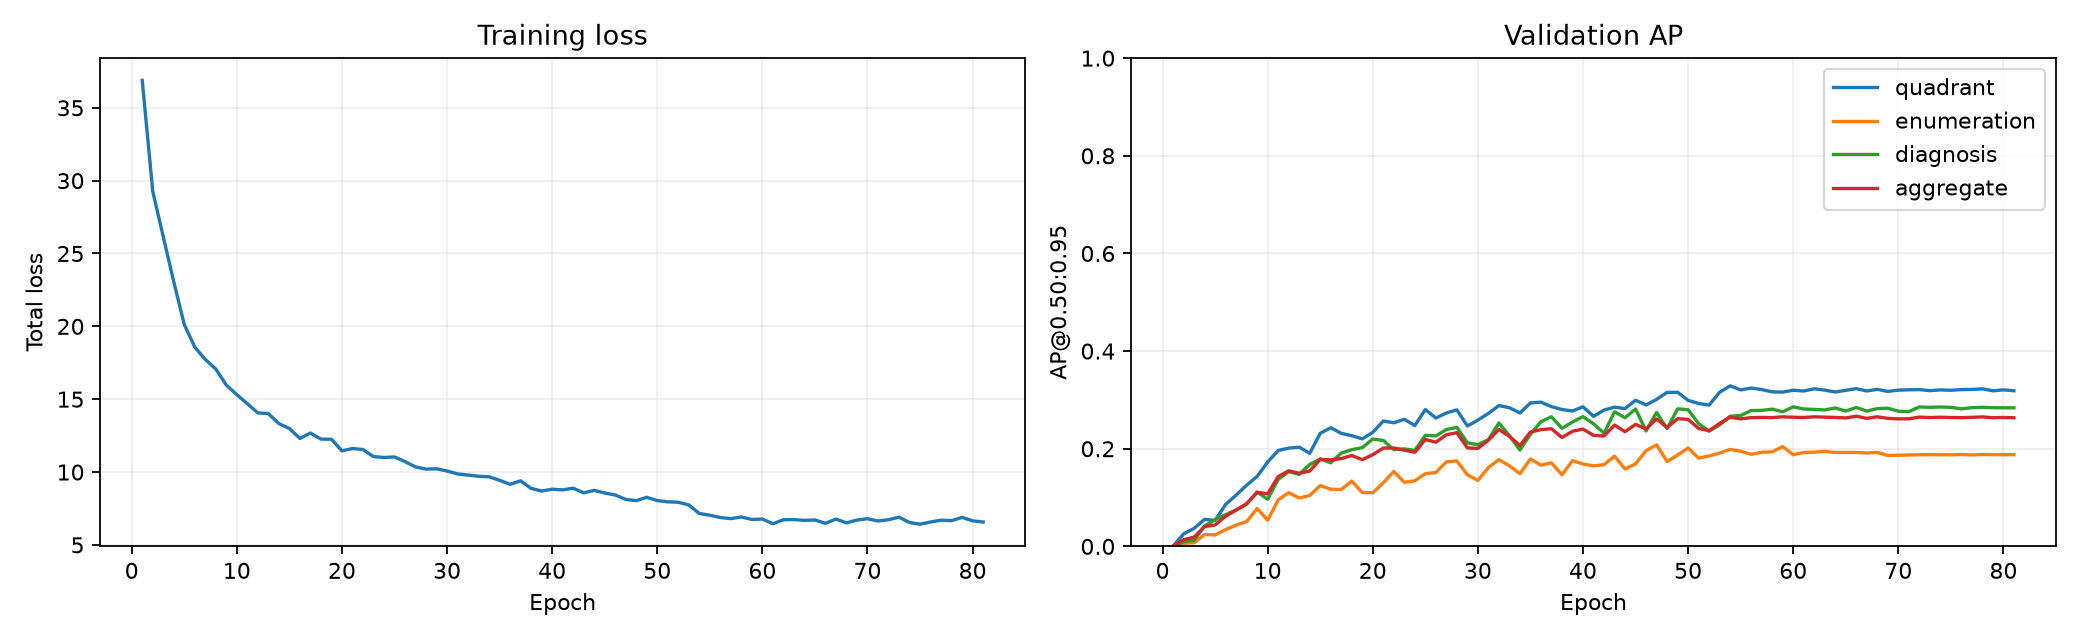

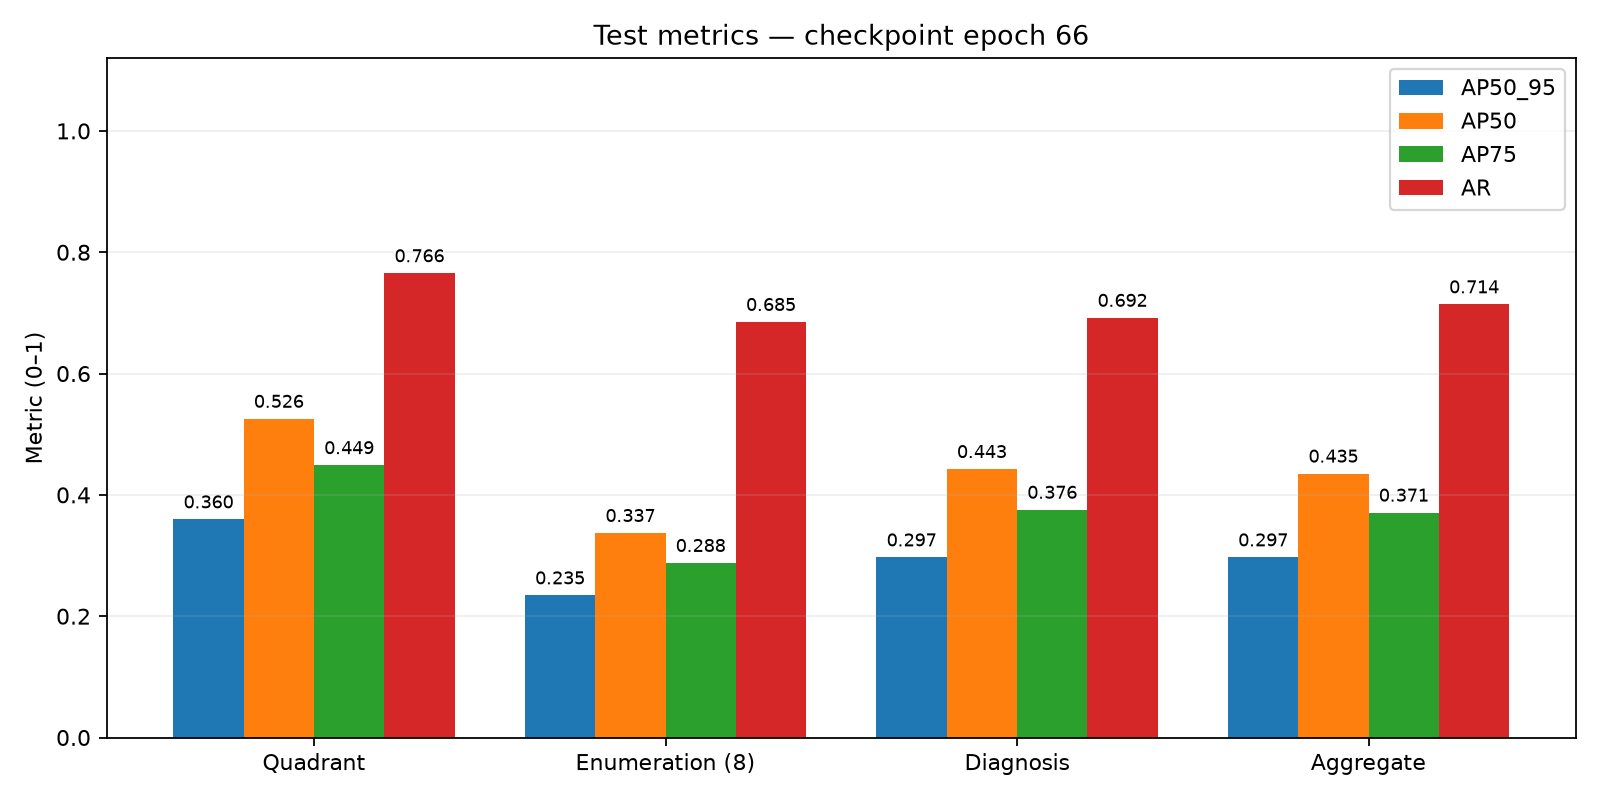

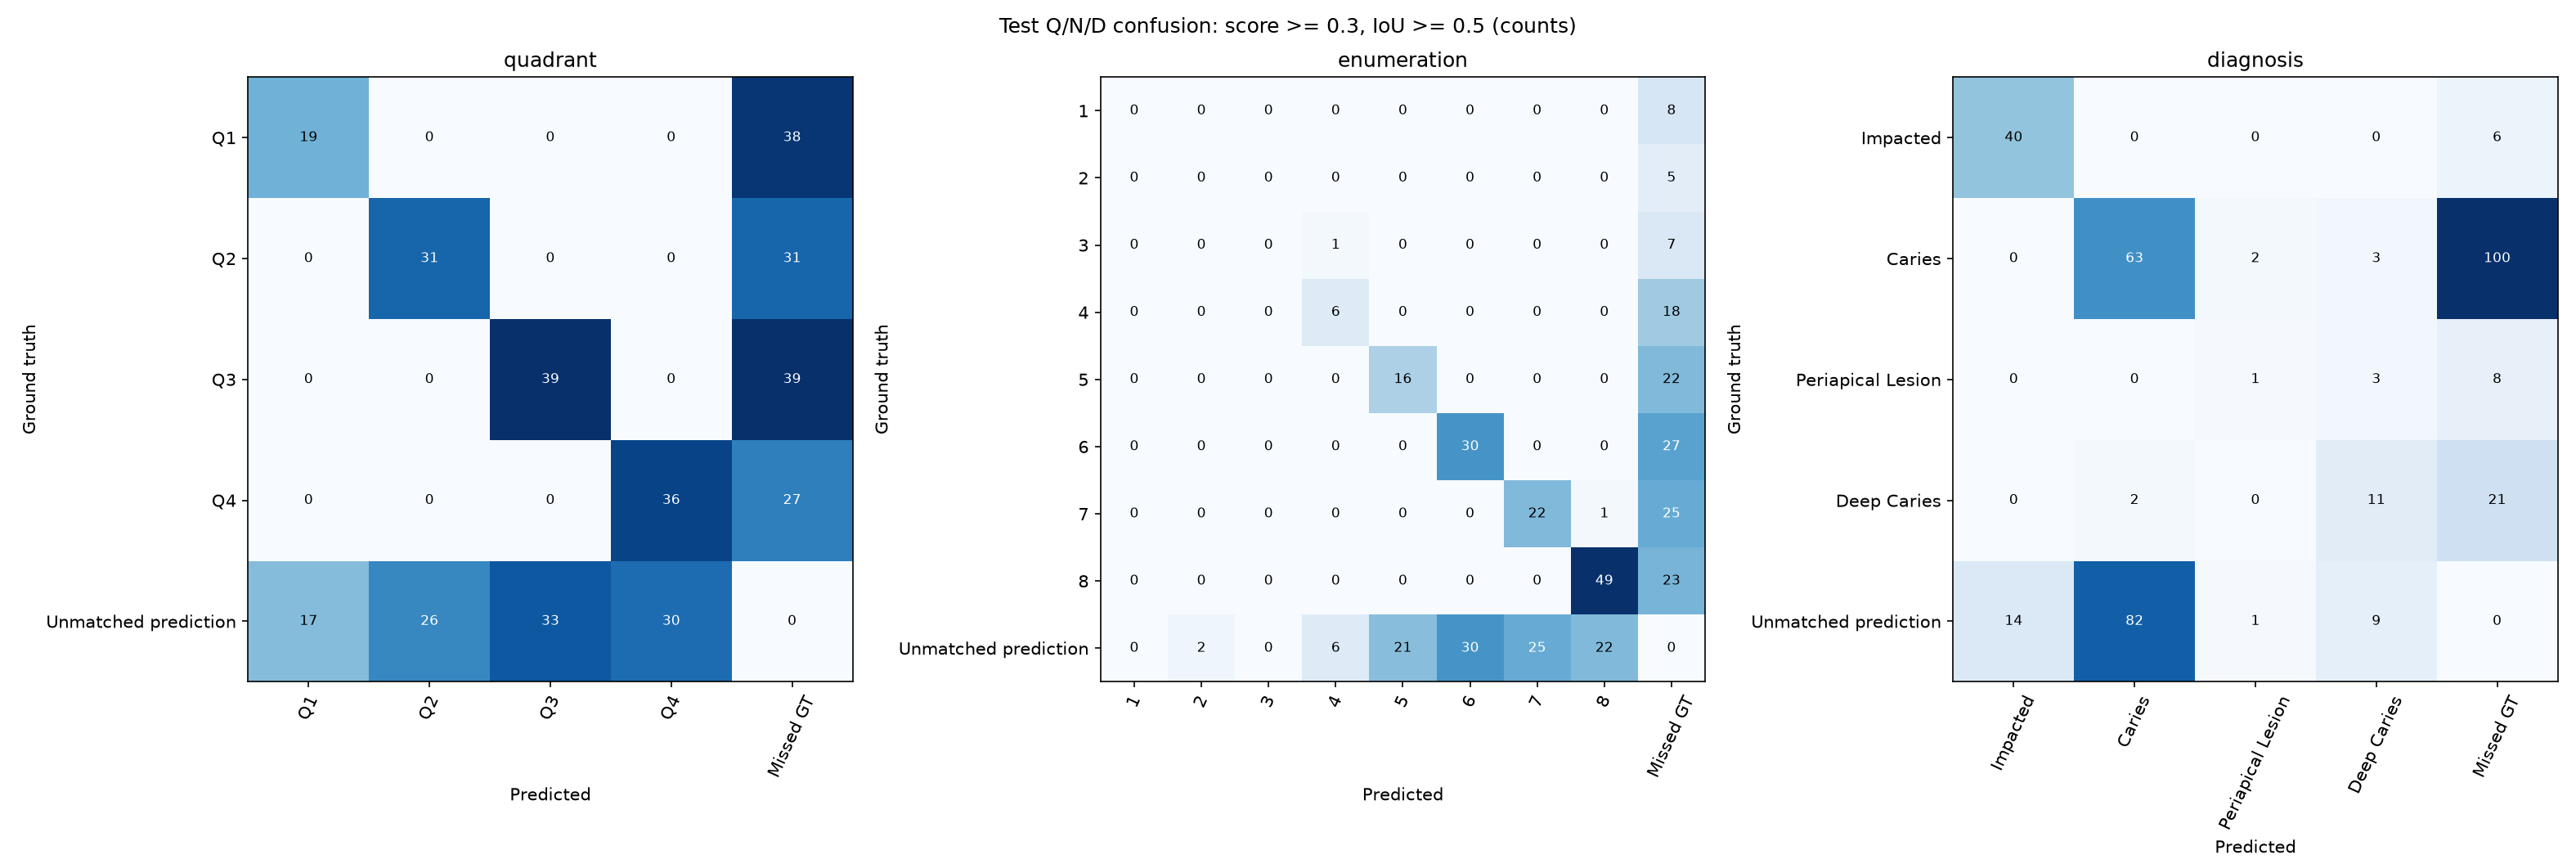

2 best + 2 worst by end-to-end QND F1; qualitative extremes, not average performance.


,group,rank,image_id,qnd_f1,qnd_precision,qnd_recall,gt_count,prediction_count,correct_qnd,false_positives,false_negatives,missed_gt,unmatched_predictions,matched_wrong_qnd,q_accuracy,n_accuracy,d_accuracy,file
0,best,1,666,1.0000,NaN,NaN,0,0,0,0,0,0,0,0,NaN,NaN,NaN,predictions/best_1_test_666.png
1,best,2,251,0.8235,0.875,0.7778,9,8,7,1,2,2,1,0,1.0,1.0,1.0,predictions/best_2_test_251.png
2,worst,1,696,0.0000,0.000,0.0000,1,1,0,1,1,0,0,1,1.0,1.0,0.0,predictions/worst_1_test_696.png
3,worst,2,693,0.0000,0.000,0.0000,1,2,0,2,1,1,2,0,NaN,NaN,NaN,predictions/worst_2_test_693.png


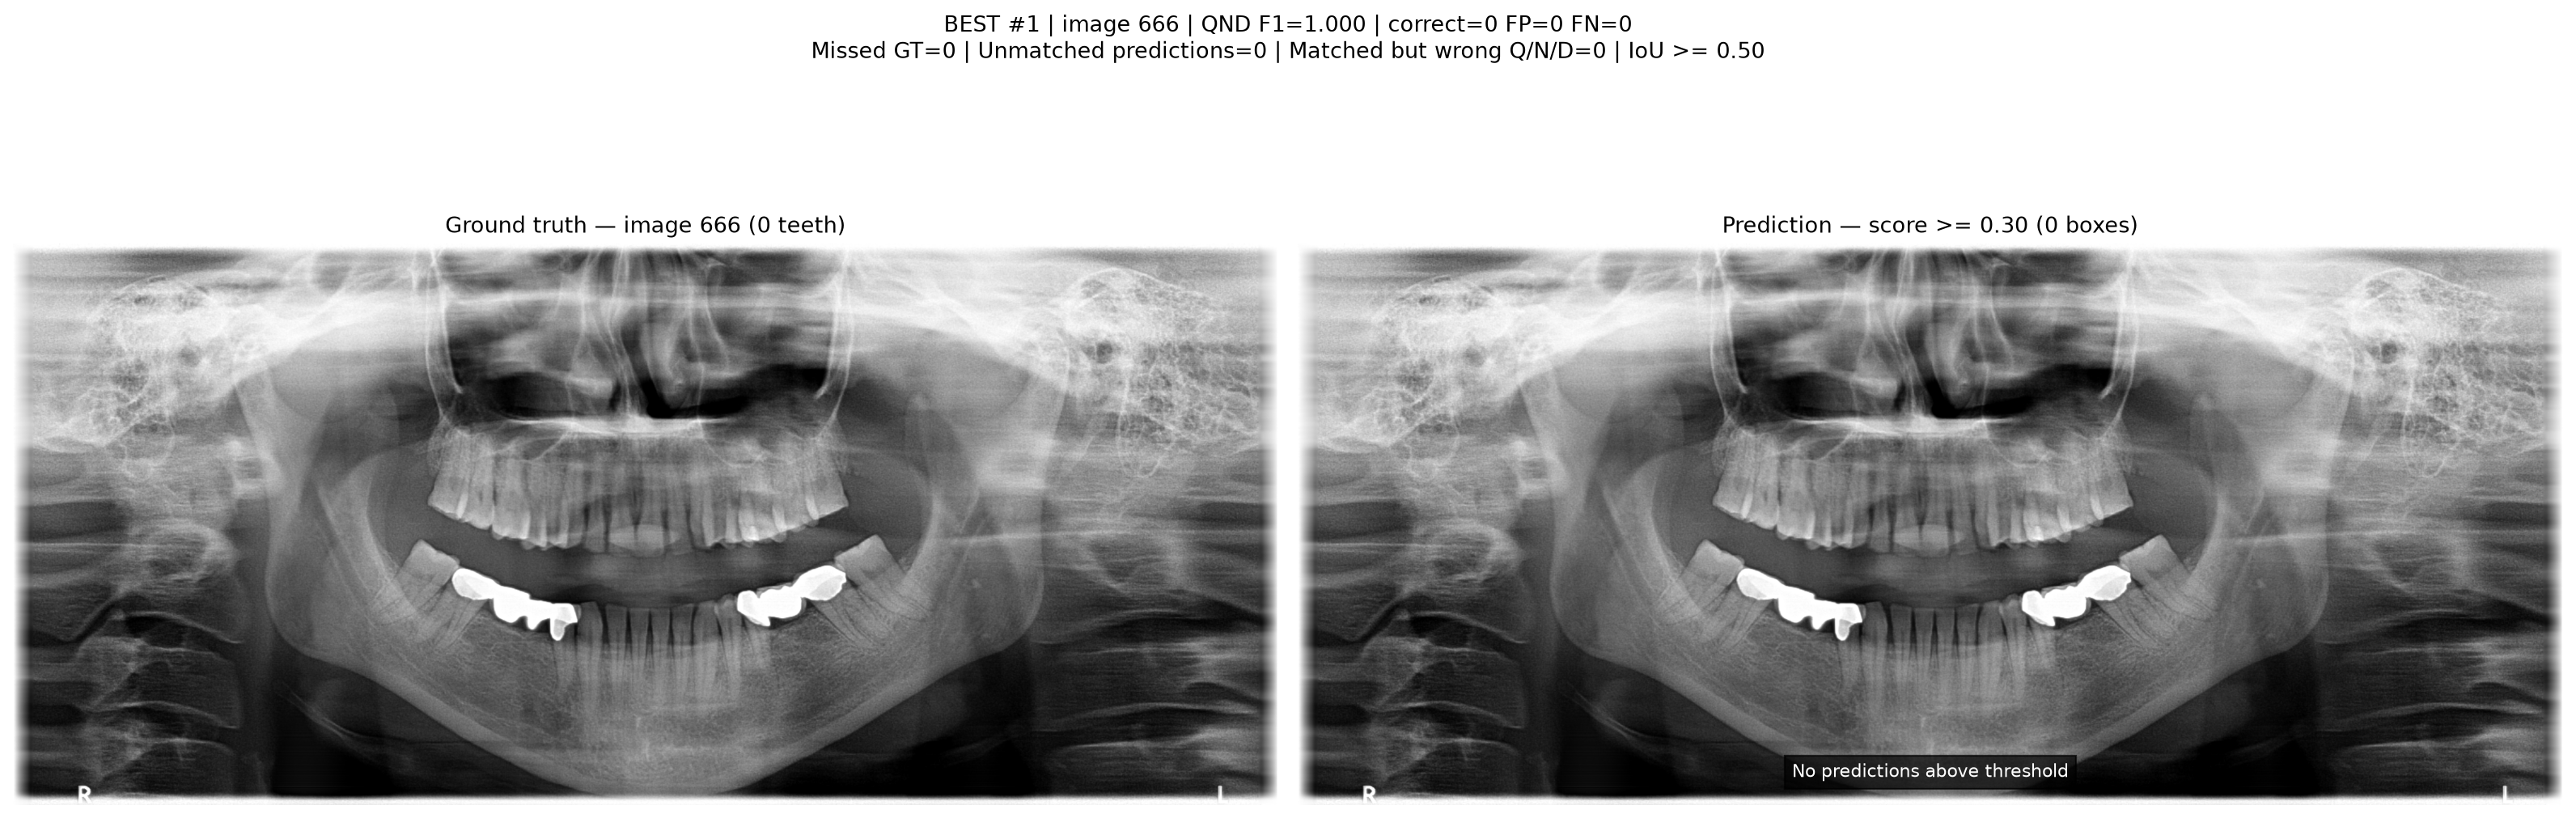

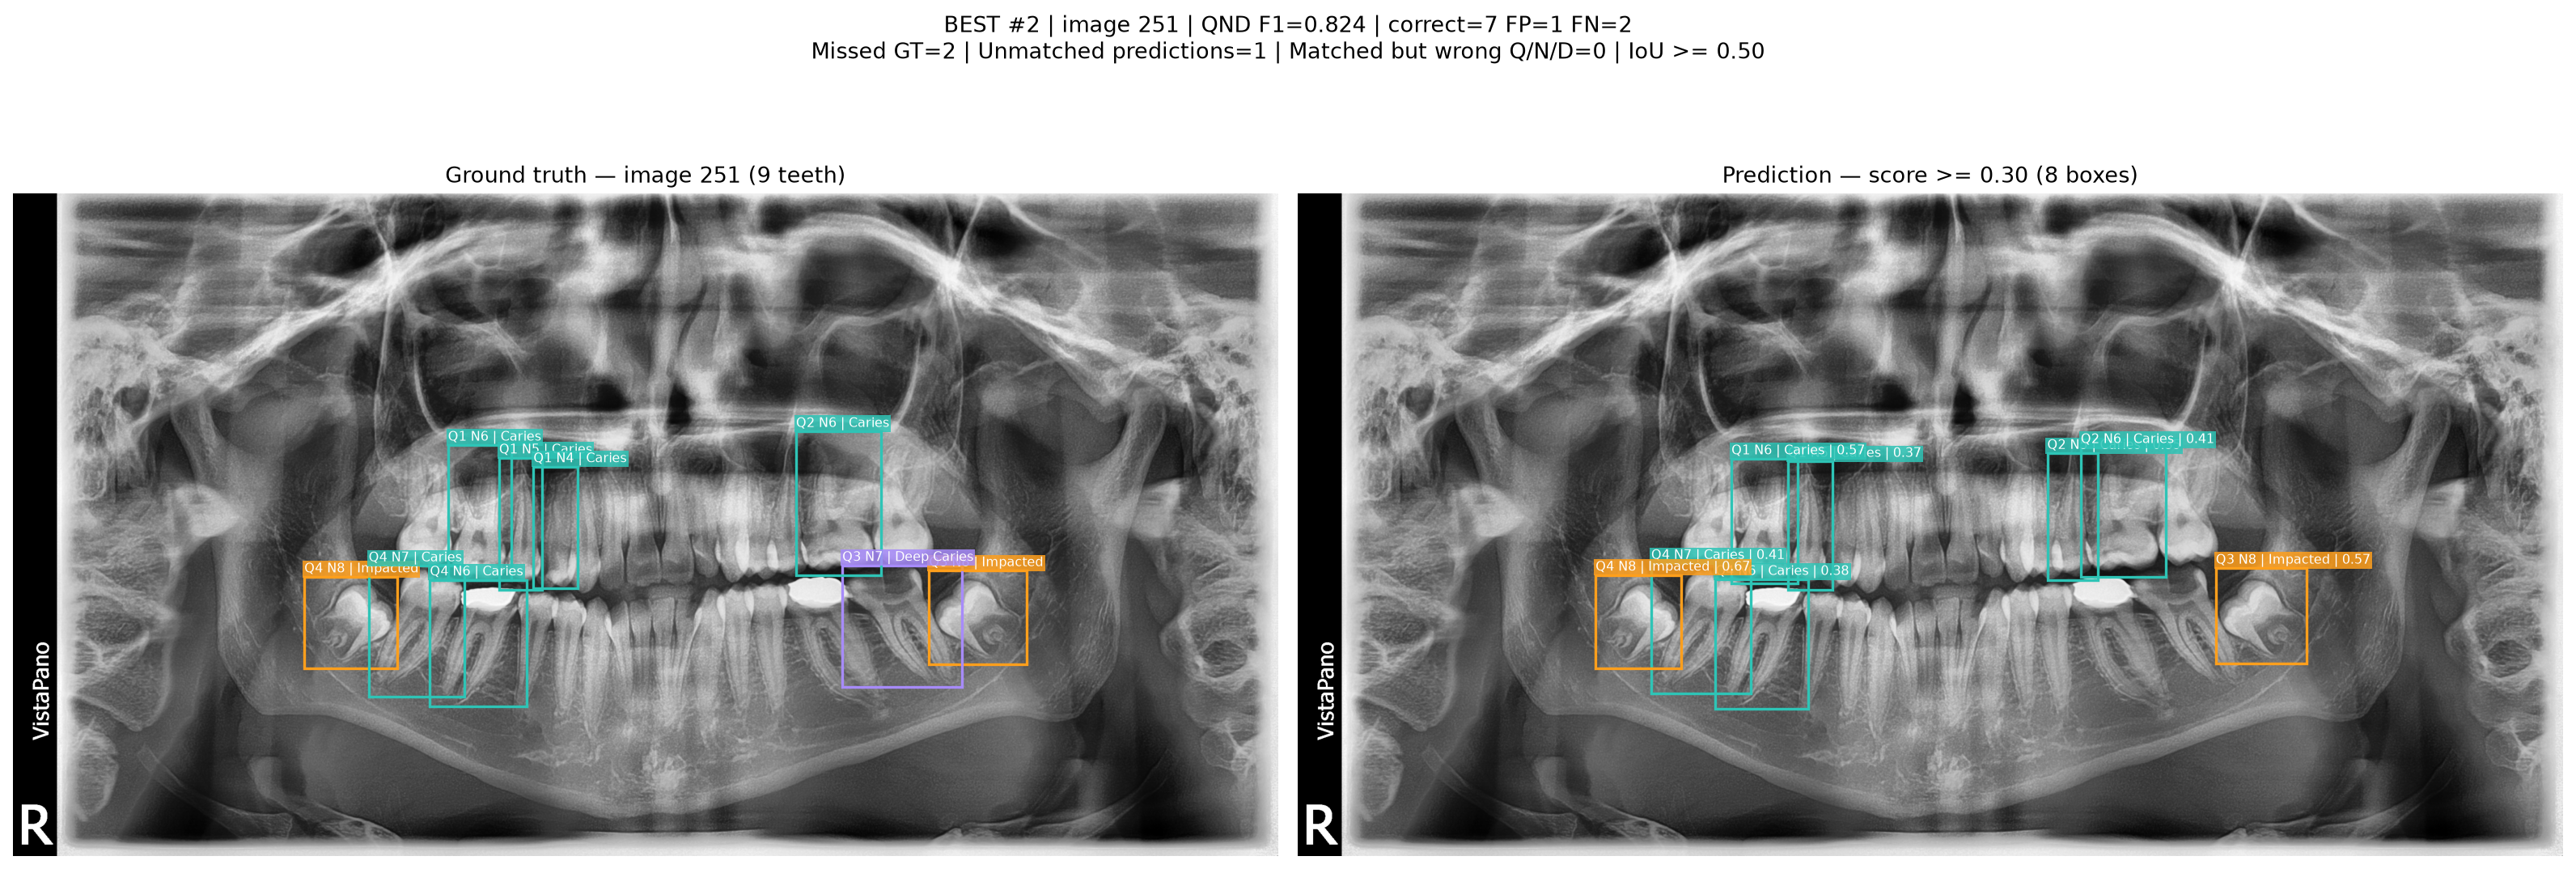

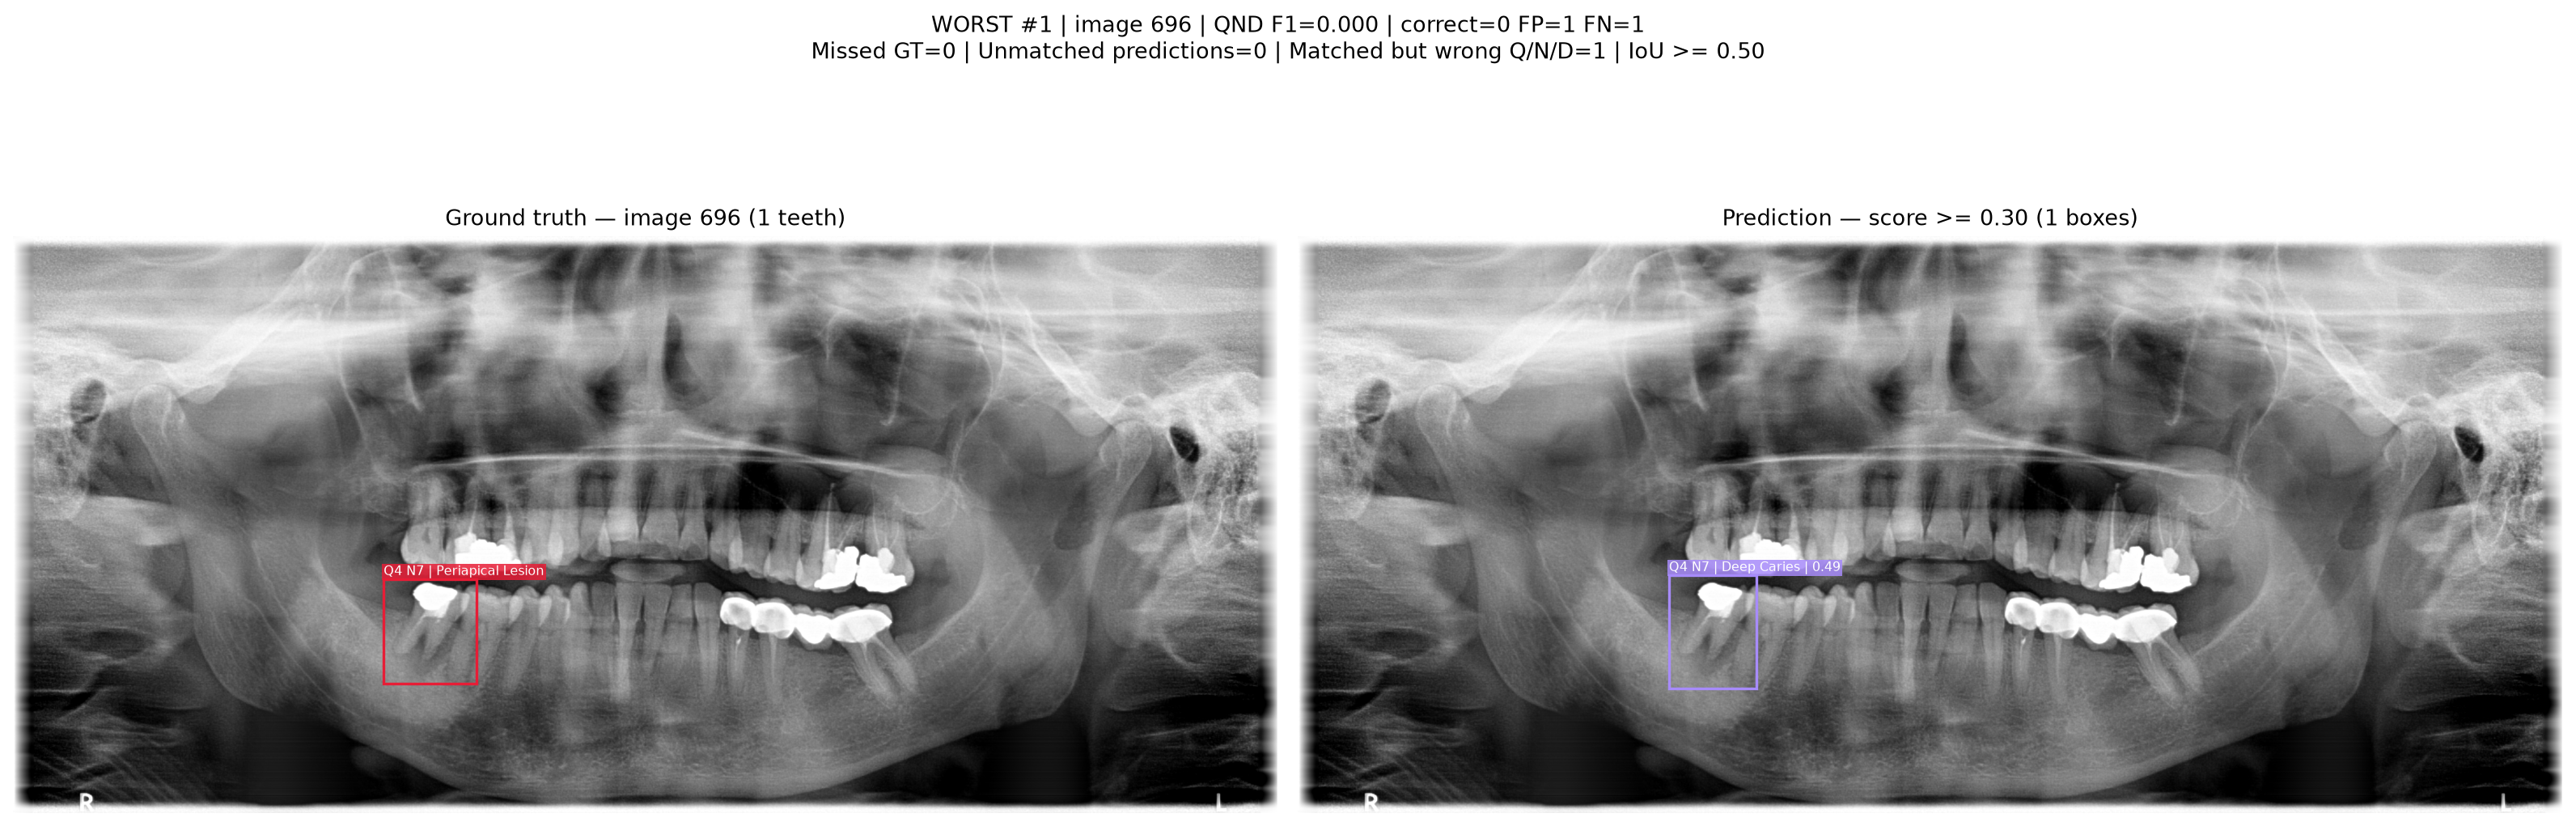

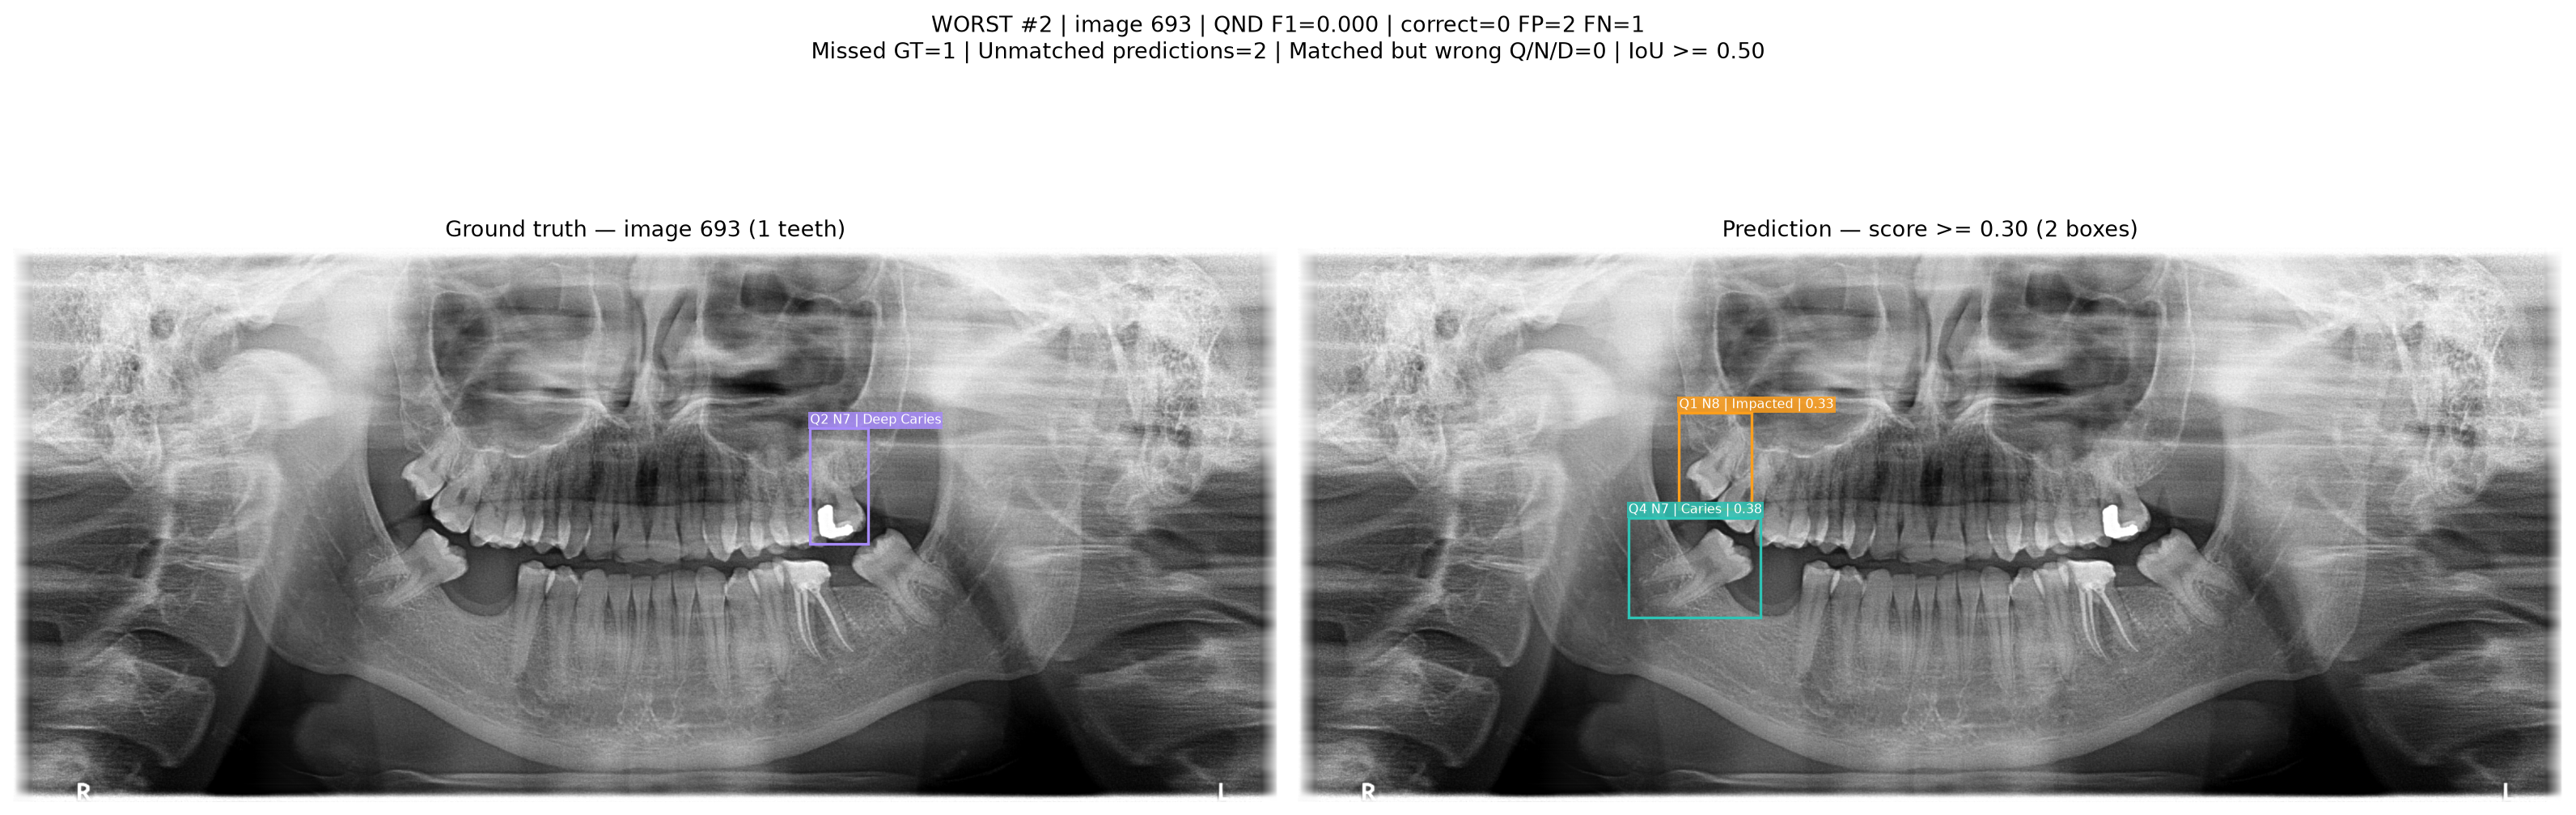

In [12]:
from IPython.display import display, Image as DisplayImage
import pandas as pd

result_dir = Path('/kaggle/working/dentex_runs/latest_run.txt').read_text().strip()
result_dir = Path(result_dir)
print('Kết quả:', result_dir)
if (result_dir/'training_summary.json').exists():
    print((result_dir/'training_summary.json').read_text())
if (result_dir/'metrics.csv').exists():
    display(pd.read_csv(result_dir/'metrics.csv').round(4))
if (result_dir/'test_classification_summary.csv').exists():
    print('Classification: fractions 0–1; matched_accuracy excludes missed GT, end_to_end_recall includes misses.')
    display(pd.read_csv(result_dir/'test_classification_summary.csv').round(4))
    import json
    report = json.loads((result_dir/'test_classification_metrics.json').read_text())
    print('Matching protocol:', report['protocol'])
    print('Localization coverage:', report['localization'])
    display(pd.read_csv(result_dir/'test_classification_per_class.csv').round(4))
for name in ('training_curves.png', 'test_metrics.png', 'test_classification_confusion.png'):
    if (result_dir/name).exists():
        display(DisplayImage(filename=str(result_dir/name)))
if (result_dir/'test_example_ranking.json').exists():
    import json
    ranking = json.loads((result_dir/'test_example_ranking.json').read_text())
    print('2 best + 2 worst by end-to-end QND F1; qualitative extremes, not average performance.')
    display(pd.DataFrame(ranking['selected']).round(4))
    for row in ranking['selected']:
        display(DisplayImage(filename=str(result_dir/row['file'])))
if not (result_dir/'test_metrics.json').exists():
    print('Chưa có metrics test. Đặt SMOKE_ONLY=False rồi Run All để train.')


## Files kết quả
- `data_audit.json`, `splits.json`: nguồn 705 ảnh, annotation hash, split 605/50/50 và thống kê nhãn.
- `best.pth`: checkpoint được chọn bằng validation AP; `last.pth`: epoch cuối.
- `history.json`, `training_curves.png`: loss/LR/AMP và validation AP theo epoch.
- `test_metrics.json`, `test_diagnosis_per_class.json`, `metrics.csv`, `test_metrics.png`: kết quả test nội bộ đủ 4 bệnh, gồm Deep Caries.
- `test_predictions.json`, `predictions/`: dự đoán và ảnh minh họa test nội bộ.
- `model_config.py`, `experiment.json`: cấu hình paper, split seed và hash script/annotation.

`CLS_SCORE_THRESHOLD` áp dụng cho metric phân loại và ảnh minh họa; COCO AP không lọc theo ngưỡng này. Không dùng test để chọn checkpoint. Không resume tự động.

- `test_metrics_dentex.json`: Quadrant / Enumeration / Diagnosis / Aggregates, mỗi nhóm có AP, AP50, AP75, AR theo schema evaluator.
- `training_summary.json`: epoch đã chạy, lý do dừng, best epoch và thông số early stopping.

- `test_classification_metrics.json`, `test_classification_summary.csv`: accuracy Q/N/D, exact-match QND, macro-F1, balanced accuracy, localization coverage và metric đầu-cuối.
- `test_classification_per_class.csv`, `test_classification_confusion.png`: precision/recall/F1 từng lớp và ma trận nhầm lẫn có bỏ sót/dự đoán thừa.
- `test_classification_candidates.json`, `test_ground_truth_joint.json`: giữ query IDs và GT để tái tính metric phân loại.

- `test_example_ranking.json`, `test_example_ranking.csv`: điểm từng ảnh test, tiêu chí xếp hạng và danh sách 2 best + 2 worst.
- `predictions/best_*.png`, `predictions/worst_*.png`: ground truth bên trái, prediction bên phải, kèm QND F1 và số lỗi. Vẽ toàn bộ prediction đủ ngưỡng, không cắt top20.
